## Activity 1: Analytical Approach

### Business Problem

The NHS must decide whether to expand infrastructure and capacity or optimise use of existing resources. This is a decision that needs to be data-informed and not opinion-driven. A specific, costly symptom sits at the centre of this: missed GP appointments. The reasons behind missed appointments need to be understood.

Two core business questions frame this analysis:
- Has there been adequate staff and capacity in the networks?
- What was the actual utilisation of resources?

A secondary, exploratory question: can external data (Twitter/X) add decision-making value?

### Translating Business Questions into Analytical Questions

| Business Question | Analytical Translation |
|---|---|
| Is capacity adequate? | Compare appointment volume against available slots/staff over time; identify periods/regions of over- or under-utilisation |
| What's actual utilisation? | Quantify appointments by service setting, context type, national category, and month/season |
| Why are appointments missed? | Isolate "did not attend" (DNA) status records; look for patterns by time, region, service setting |
| Does Twitter data help? | Extract top hashtags/themes; assess whether they align with or explain patterns seen in structured data |


### Initial Investigation Steps

1. Read metadata in full before touching the data to understand field definitions and known data quality issues.
2. Profile each dataset: shape, dtypes, nulls, unique categorical values, date range.
3. Identify a common key across datasets to assess if/how they can be joined.
4. Standardise date fields and category labels across datasets, as naming may differ between files.
5. Build simple aggregate views (counts by month, by category) before attempting trend or comparative analysis.

# Assignment activity 2: Importing & Exploring Data

In [109]:
# Import neccesary libraries
import pandas as pd
import numpy as np

# Ignore warnings.
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Import the actual_duration data set and check dimensions

ad = pd.read_csv('actual_duration.csv')
ad

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments
0,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,31-60 Minutes,364
1,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,21-30 Minutes,619
2,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,6-10 Minutes,1698
3,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,Unknown / Data Quality,1277
4,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,16-20 Minutes,730
...,...,...,...,...,...,...,...,...
137788,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,31-60 Minutes,430
137789,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,21-30 Minutes,751
137790,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,16-20 Minutes,921
137791,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,11-15 Minutes,1439


In [3]:
# check data types
ad.dtypes

sub_icb_location_code        object
sub_icb_location_ons_code    object
sub_icb_location_name        object
icb_ons_code                 object
region_ons_code              object
appointment_date             object
actual_duration              object
count_of_appointments         int64
dtype: object

In [4]:
# Check for missing values

ad_na = ad[ad.isna().any(axis = 1)]
ad_na.shape

(0, 8)

The output shows that there are no rows with NAN in 8 columns.

In [5]:
# Descriptive Statistics

ad.describe()

,count_of_appointments
count,137793.000000
mean,1219.080011
std,1546.902956
min,1.000000
25%,194.000000
50%,696.000000
75%,1621.000000
max,15400.000000


In [6]:
# metadata of the data set
ad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137793 entries, 0 to 137792
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   sub_icb_location_code      137793 non-null  object
 1   sub_icb_location_ons_code  137793 non-null  object
 2   sub_icb_location_name      137793 non-null  object
 3   icb_ons_code               137793 non-null  object
 4   region_ons_code            137793 non-null  object
 5   appointment_date           137793 non-null  object
 6   actual_duration            137793 non-null  object
 7   count_of_appointments      137793 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 8.4+ MB


In [7]:
# Import the appointments_regional data set and check dimensions

ar = pd.read_csv('appointments_regional.csv')
ar

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,E54000034,2020-01,Attended,GP,Face-to-Face,1 Day,8107
1,E54000034,2020-01,Attended,GP,Face-to-Face,15 to 21 Days,6791
2,E54000034,2020-01,Attended,GP,Face-to-Face,2 to 7 Days,20686
3,E54000034,2020-01,Attended,GP,Face-to-Face,22 to 28 Days,4268
4,E54000034,2020-01,Attended,GP,Face-to-Face,8 to 14 Days,11971
...,...,...,...,...,...,...,...
596816,E54000050,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,E54000050,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,E54000050,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,E54000050,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [8]:
# check data types
ar.dtypes

icb_ons_code                         object
appointment_month                    object
appointment_status                   object
hcp_type                             object
appointment_mode                     object
time_between_book_and_appointment    object
count_of_appointments                 int64
dtype: object

In [9]:
# metadata of the data set
ar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 596821 entries, 0 to 596820
Data columns (total 7 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   icb_ons_code                       596821 non-null  object
 1   appointment_month                  596821 non-null  object
 2   appointment_status                 596821 non-null  object
 3   hcp_type                           596821 non-null  object
 4   appointment_mode                   596821 non-null  object
 5   time_between_book_and_appointment  596821 non-null  object
 6   count_of_appointments              596821 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 31.9+ MB


In [10]:
# Check for missing values

ar_na = ar[ar.isna().any(axis = 1)]
ar_na.shape

(0, 7)

The output shows that there are no rows with NAN in 7 columns.

In [11]:
# Descriptive Statistics

ar.describe()

,count_of_appointments
count,596821.000000
mean,1244.601857
std,5856.887042
min,1.000000
25%,7.000000
50%,47.000000
75%,308.000000
max,211265.000000


In [108]:
# Import the national_categories data set 

nc = pd.read_csv('national_categories.csv')
nc.head()

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month
0,02/08/2021,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08
1,02/08/2021,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08
2,02/08/2021,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08
3,02/08/2021,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08
4,02/08/2021,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08


In [13]:
# check data types
nc.dtypes

appointment_date         object
icb_ons_code             object
sub_icb_location_name    object
service_setting          object
context_type             object
national_category        object
count_of_appointments     int64
appointment_month        object
dtype: object

In [14]:
# metadata of the data set
nc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 817394 entries, 0 to 817393
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   appointment_date       817394 non-null  object
 1   icb_ons_code           817394 non-null  object
 2   sub_icb_location_name  817394 non-null  object
 3   service_setting        817394 non-null  object
 4   context_type           817394 non-null  object
 5   national_category      817394 non-null  object
 6   count_of_appointments  817394 non-null  int64 
 7   appointment_month      817394 non-null  object
dtypes: int64(1), object(7)
memory usage: 49.9+ MB


In [15]:
# Check for missing values

nc_na = nc[nc.isna().any(axis = 1)]
nc_na.shape

(0, 8)

The output shows that there are no rows with NAN in 8 columns.

In [16]:
# Descriptive Statistics

nc.describe()

,count_of_appointments
count,817394.000000
mean,362.183684
std,1084.576600
min,1.000000
25%,7.000000
50%,25.000000
75%,128.000000
max,16590.000000


# 2.1 Exploring the data set

## a. How many locations are there?

In [17]:
# Number of unique locations in actual_duration.csv

num_locations_ad = ad['sub_icb_location_name'].nunique()
print(f"Unique locations in actual_duration: {num_locations_ad}")

Unique locations in actual_duration: 106


In [18]:
# Number of unique locations in national_categories.csv

num_locations_nc = nc['sub_icb_location_name'].nunique()
print(f"Unique locations in national_categories: {num_locations_nc}")

Unique locations in national_categories: 106


In [19]:
# Number of unique higher-level regions in appointments_regional.csv

num_regions_ar = ar['icb_ons_code'].nunique()
print(f"Unique ICB regions in appintments_regional: {num_regions_ar}")

Unique ICB regions in appintments_regional: 42


## b. Top 5 locations by number of appointments

In [20]:
# Top 5 locations by total appointment count (national_categories.csv)

top5_locations_nc = (nc.groupby('sub_icb_location_name')['count_of_appointments'].sum()
                     .sort_values(ascending=False).head(5))
print(top5_locations_nc)

sub_icb_location_name
NHS North West London ICB - W2U3Z              12142390
NHS North East London ICB - A3A8R               9588891
NHS Kent and Medway ICB - 91Q                   9286167
NHS Hampshire and Isle Of Wight ICB - D9Y0V     8288102
NHS South East London ICB - 72Q                 7850170
Name: count_of_appointments, dtype: int64


In [21]:
# Cross-check Top 5 locations by total appointment count against actual_duration.csv

top5_locations_ad = (ad.groupby('sub_icb_location_name')['count_of_appointments'].sum()
                     .sort_values(ascending=False).head(5))
print(top5_locations_ad)

sub_icb_location_name
NHS North West London ICB - W2U3Z              6976986
NHS North East London ICB - A3A8R              5341883
NHS Kent and Medway ICB - 91Q                  5209641
NHS Hampshire and Isle Of Wight ICB - D9Y0V    4712737
NHS South East London ICB - 72Q                4360079
Name: count_of_appointments, dtype: int64


**Finding:** The top 5 locations by appointment volume are identical, and in the same rank 
order, across both `national_categories` and `actual_duration`.

All five top locations are large London and South East ICBs, which likely reflects these 
areas having larger registered patient populations rather than indicating under-capacity.

The raw counts differ between datasets, which is expected because the two 
datasets break appointments down differently (by service setting/category vs by duration 
band) and are not necessarily counting the same underlying population of appointments.

## c. Counts of service settings, context types, national categories, appointment statuses

In [22]:
# From national_categories.csv
print(f"Service settings: {nc['service_setting'].nunique()}")
print(nc['service_setting'].unique())

print(f"\nContext types: {nc['context_type'].nunique()}")
print(nc['context_type'].unique())

print(f"\nNational category: {nc['national_category'].nunique()}")
print(nc['national_category'].unique())

# From appointments_regional.csv
print(f"\nAppointment status: {ar['appointment_status'].nunique()}")
print(ar['appointment_status'].unique())

Service settings: 5
['Primary Care Network' 'Other' 'General Practice' 'Unmapped'
 'Extended Access Provision']

Context types: 3
['Care Related Encounter' 'Unmapped' 'Inconsistent Mapping']

National category: 18
['Patient contact during Care Home Round' 'Planned Clinics' 'Home Visit'
 'General Consultation Acute' 'Structured Medication Review'
 'Care Home Visit' 'Unmapped' 'Clinical Triage'
 'Planned Clinical Procedure' 'Inconsistent Mapping'
 'Care Home Needs Assessment & Personalised Care and Support Planning'
 'General Consultation Routine'
 'Service provided by organisation external to the practice'
 'Unplanned Clinical Activity' 'Social Prescribing Service'
 'Non-contractual chargeable work'
 'Group Consultation and Group Education' 'Walk-in']

Appointment status: 3
['Attended' 'DNA' 'Unknown']


**Finding:** There are 5 service settings, 3 context types, and 18 national categories. 
Appointment status includes Attended, DNA (did not attend), and Unknown.

In [32]:
# Check for 'Unknown' style values hiding as valid categories

print("actual_duration value counts:")
print(ad['actual_duration'].value_counts())

print("\nappointment_status value counts:")
print(ar['appointment_status'].value_counts())

print("\nhcp_type value counts:")
print(ar['hcp_type'].value_counts())

print("\nappointment_mode value counts:")
print(ar['appointment_mode'].value_counts())

actual_duration value counts:
actual_duration
Unknown / Data Quality    20161
1-5 Minutes               19909
6-10 Minutes              19902
11-15 Minutes             19738
16-20 Minutes             19534
21-30 Minutes             19452
31-60 Minutes             19097
Name: count, dtype: int64

appointment_status value counts:
appointment_status
Attended    232137
Unknown     201324
DNA         163360
Name: count, dtype: int64

hcp_type value counts:
hcp_type
Other Practice staff    241557
GP                      226036
Unknown                 129228
Name: count, dtype: int64

appointment_mode value counts:
appointment_mode
Face-to-Face    180410
Telephone       166483
Home Visit      111194
Unknown          79147
Video/Online     59587
Name: count, dtype: int64


**Data quality note:** Although no columns contain NaN values, several categorical fields 
contain a literal "Unknown" category. This is disguised missingness will be handled explicitly
during analysis and retained as its own category for reporting on data quality itself rather than ignored. 

Also, `appointment_date` formats differ across datasets. `actual_duration.csv` uses 
"01-Dec-21" while `national_categories.csv` uses "02/08/2021" (day/month/year). These will need to 
be parsed into a consistent datetime format before trend analysis.

## d. Other potentially useful columns

**Other features worth carrying into later analysis:**
- `time_between_book_and_appointment` (appointments_regional): This is directly relevant to the 
  "adequate capacity" question; long booking-to-appointment gaps could indicate under-capacity, 
  and this field may also correlate with missed appointments.
- `appointment_mode` (appointments_regional): Face-to-Face vs remote modes. This is relevant to 
  understanding how capacity is being used.
- `actual_duration` (actual_duration.csv): appointment length bands; combined with count, this 
  gives a proxy for total clinical time consumed, which is more informative than raw appointment 
  counts alone for a capacity argument.

# Assignment Activity 3

### Q1. Between what dates were appointments scheduled?

In [23]:
# check date formats for all DataFrames

print("ad appointment_date sample:", ad['appointment_date'].head(3).tolist())
print("ad appointment_date dtype:", ad['appointment_date'].dtype)

print("\nnc appointment_date sample:", nc['appointment_date'].head(3).tolist())
print("nc appointment_date dtype:", nc['appointment_date'].dtype)

print("\nar appointment_month sample:", ar['appointment_month'].head(3).tolist())
print("ar appointment_month dtype:", ar['appointment_month'].dtype)

ad appointment_date sample: ['01-Dec-21', '01-Dec-21', '01-Dec-21']
ad appointment_date dtype: object

nc appointment_date sample: ['02/08/2021', '02/08/2021', '02/08/2021']
nc appointment_date dtype: object

ar appointment_month sample: ['2020-01', '2020-01', '2020-01']
ar appointment_month dtype: object


In [24]:
# convert dates to datetime format

# Convert actual_duration.csv (format: 01-Dec-21)
ad['appointment_date'] = pd.to_datetime(ad['appointment_date'], format='%d-%b-%y')

# Convert national_categories.csv (format: 02/08/2021)
nc['appointment_date'] = pd.to_datetime(nc['appointment_date'], format='%d/%m/%Y')

# Convert appointments_regional.csv (format: 2020-01, month-level only)
ar['appointment_month'] = pd.to_datetime(ar['appointment_month'], format='%Y-%m')

In [25]:
# check the conversion

print("ad appointment_date dtype:", ad['appointment_date'].dtype)
print(ad['appointment_date'].head())

print("\nnc appointment_date dtype:", nc['appointment_date'].dtype)
print(nc['appointment_date'].head())

print("\nar appointment_month dtype:", ar['appointment_month'].dtype)
print(ar['appointment_month'].head())

ad appointment_date dtype: datetime64[ns]
0   2021-12-01
1   2021-12-01
2   2021-12-01
3   2021-12-01
4   2021-12-01
Name: appointment_date, dtype: datetime64[ns]

nc appointment_date dtype: datetime64[ns]
0   2021-08-02
1   2021-08-02
2   2021-08-02
3   2021-08-02
4   2021-08-02
Name: appointment_date, dtype: datetime64[ns]

ar appointment_month dtype: datetime64[ns]
0   2020-01-01
1   2020-01-01
2   2020-01-01
3   2020-01-01
4   2020-01-01
Name: appointment_month, dtype: datetime64[ns]


In [44]:
# Identify the earliest and latest appointment dates 

# Date range in actual_duration.csv
print(f"actual_duration date range: {ad['appointment_date'].min()} to {ad['appointment_date'].max()}")

# Date range in national_categories.csv
print(f"national_categories date range: {nc['appointment_date'].min()} to {nc['appointment_date'].max()}")

# Month range in appointments_regional.csv
print(f"appointments_regional month range: {ar['appointment_month'].min()} to {ar['appointment_month'].max()}")

actual_duration date range: 2021-12-01 00:00:00 to 2022-06-30 00:00:00
national_categories date range: 2021-08-01 00:00:00 to 2022-06-30 00:00:00
appointments_regional month range: 2020-01-01 00:00:00 to 2022-06-01 00:00:00


**Finding:** The three datasets cover different, overlapping date ranges:

- `actual_duration`: 2021-12-01 to 2022-06-30 (7 months)
- `national_categories`: 2021-08-01 to 2022-06-30 (11 months)
- `appointments_regional`: 2020-01-01 to 2022-06-01 (29 months, month-level only)

`appointments_regional` has by far the longest history, starting almost two years before 
the other two datasets. `national_categories` starts four months earlier than 
`actual_duration`. All three datasets converge on the same end point, 2022-06.

### Q2. Which service setting reported the most appointments in North West London from 1 January to 1 June 2022?

In [26]:
# Ceate a subset in nc for NHS North West London ICB, 1 Jan 2022 to 1 Jun 2022

nwl_subset = nc[
    (nc['sub_icb_location_name'] == 'NHS North West London ICB - W2U3Z') &
    (nc['appointment_date'] >= '2022-01-01') &
    (nc['appointment_date'] <= '2022-06-01')
]

nwl_subset.shape

(5936, 8)

In [27]:
# print the subset to check the filter worked

print(nwl_subset['sub_icb_location_name'].unique())
print(nwl_subset['appointment_date'].min(), "to", nwl_subset['appointment_date'].max())

['NHS North West London ICB - W2U3Z']
2022-01-01 00:00:00 to 2022-06-01 00:00:00


In [28]:
# Total appointments per service setting within this subset
nwl_by_setting = (
    nwl_subset.groupby('service_setting')['count_of_appointments']
    .sum()
    .sort_values(ascending=False)
)

print(nwl_by_setting)

service_setting
General Practice             4804239
Unmapped                      391106
Other                         152897
Primary Care Network          109840
Extended Access Provision      98159
Name: count_of_appointments, dtype: int64


In [29]:
top_setting = nwl_by_setting.idxmax()
top_setting_count = nwl_by_setting.max()

print(f"Top service setting: {top_setting} with {top_setting_count:,} appointments")

Top service setting: General Practice with 4,804,239 appointments


**Finding:** Between 1 January and 1 June 2022, **General Practice** accounted for the most 
appointments in NHS North West London ICB, with **4,804,239 appointments** 

General Practice dominates, accounting for roughly 87% of all appointments 
in this location and period.
General Practice is the primary point of contact for most patients, so its dominance here 
isn't shocking.

**Data quality note worth flagging:** "Unmapped" is the *second*-largest category at 7% 
(391,106 appointments) which is larger than three of the four named service settings combined. 
This shows the data quality concern raised earlier: a meaningful share of 
appointment volume can't currently be attributed to a specific service setting, which limits 
confidence in any conclusion about *where* capacity pressure sits, beyond "mostly General 
Practice."

### Q3. Which month had the highest number of appointments?

In [30]:
# Extract year and month as separate components from national_categories
nc['year'] = nc['appointment_date'].dt.year
nc['month'] = nc['appointment_date'].dt.month

nc[['appointment_date', 'year', 'month']].head()

,appointment_date,year,month
0,2021-08-02,2021,8
1,2021-08-02,2021,8
2,2021-08-02,2021,8
3,2021-08-02,2021,8
4,2021-08-02,2021,8


In [31]:
# group appointments by year and month and sum the appointments

# Total appointments per year-month from national_categories

appointments_by_month = (
    nc.groupby(['year', 'month'])['count_of_appointments']
    .sum()
    .sort_values(ascending=False)
)

print(appointments_by_month)

year  month
2021  11       30405070
      10       30303834
2022  3        29595038
2021  9        28522501
2022  5        27495508
      6        25828078
      1        25635474
      2        25355260
2021  12       25140776
2022  4        23913060
2021  8        23852171
Name: count_of_appointments, dtype: int64


In [32]:
top_month = appointments_by_month.idxmax()  # returns a tuple: (year, month)
top_month_count = appointments_by_month.max()

print(f"Highest month: {top_month[0]}-{top_month[1]:02d} with {top_month_count:,} appointments")

Highest month: 2021-11 with 30,405,070 appointments


**Finding:** **November 2021** had the highest number of appointments, with **30,405,070** 
recorded, which is narrowly ahead of October 2021 (30,303,834), the second-highest month. This is closer to a two-month peak (October–November 2021) than a single standout month.

**Pattern:** the two highest months (Oct–Nov 2021) fit a possible seasonal 
explanation, which is increased GP demand heading into winter/flu season. However, this doesn't hold 
as a clean seasonal curve, as December 2021 drops to the third-lowest month in the dataset despite being in the middle of the assumed "winter demand" period. This dip is more likely explained by reduced clinic operating days around the Christmas/New Year holiday period than by lower underlying patient demand.

### Q4. What was the total number of records per month?

In [33]:
# count total number of records (rows) per month for national_categories

nc['year_month'] = nc['appointment_date'].dt.to_period('M')
records_by_month_nc = (
    nc.groupby('year_month')
    .size()
    .sort_index()
)

print(records_by_month_nc)

year_month
2021-08    69999
2021-09    74922
2021-10    74078
2021-11    77652
2021-12    72651
2022-01    71896
2022-02    71769
2022-03    82822
2022-04    70012
2022-05    77425
2022-06    74168
Freq: M, dtype: int64


In [34]:
# count total records per month for actual_duration

ad['year_month'] = ad['appointment_date'].dt.to_period('M')

records_by_month_ad = (
    ad.groupby('year_month')
    .size()
    .sort_index()
)

print(records_by_month_ad)

year_month
2021-12    19507
2022-01    19643
2022-02    18974
2022-03    21236
2022-04    19078
2022-05    20128
2022-06    19227
Freq: M, dtype: int64


In [35]:
# count total records per month for appointments_regional

ar['year_month'] = ar['appointment_month'].dt.to_period('M')

records_by_month_ar = (
    ar.groupby('year_month')
    .size()
    .sort_index()
)

print(records_by_month_ar)

year_month
2020-01    20889
2020-02    20689
2020-03    21350
2020-04    19124
2020-05    18338
2020-06    18844
2020-07    19502
2020-08    19247
2020-09    20043
2020-10    20122
2020-11    19675
2020-12    19394
2021-01    19319
2021-02    18949
2021-03    19369
2021-04    19452
2021-05    19384
2021-06    19814
2021-07    19899
2021-08    19786
2021-09    20441
2021-10    20562
2021-11    20766
2021-12    20393
2022-01    20225
2022-02    20133
2022-03    20532
2022-04    20073
2022-05    20276
2022-06    20231
Freq: M, dtype: int64


In [36]:
# Compare the results across the different datasets.

records_comparison = pd.DataFrame({
    'actual_duration': records_by_month_ad,
    'national_categories': records_by_month_nc,
    'appointments_regional': records_by_month_ar
})

print(records_comparison)

            actual_duration  national_categories  appointments_regional
year_month                                                             
2020-01                 NaN                  NaN                  20889
2020-02                 NaN                  NaN                  20689
2020-03                 NaN                  NaN                  21350
2020-04                 NaN                  NaN                  19124
2020-05                 NaN                  NaN                  18338
2020-06                 NaN                  NaN                  18844
2020-07                 NaN                  NaN                  19502
2020-08                 NaN                  NaN                  19247
2020-09                 NaN                  NaN                  20043
2020-10                 NaN                  NaN                  20122
2020-11                 NaN                  NaN                  19675
2020-12                 NaN                  NaN                

**Finding:** The three datasets differ substantially in record volume per month.

`appointments_regional` has a record count of roughly 18,300–21,400 per month, and is 
remarkably stable across its entire 2.5 year span (Jan 2020 - Jun 2022) which suggests its reporting structure has 
stayed consistent over time.

`national_categories` has a much higher record count per month (roughly 70,000 - 83,000, more 
than 3x `appointments_regional`), reflecting the fact that it breaks appointments down by 
additional dimensions (service_setting, context_type, national_category) that create many 
more row combinations per month than `appointments_regional`.

`actual_duration` has the lowest record count of the three (roughly 18,900 - 21,200 per 
month, similar in scale to `appointments_regional`), and only begins in 2021-12.

# Assignment Activity 4: Visualising and identifying initial trends

In [37]:
# Import visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent plot style and default figure size for all charts in this notebook
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [38]:
# Confirm the datetime and year_month columns exist
print(nc.dtypes[['appointment_date', 'year_month']])
nc[['appointment_date', 'year_month', 'service_setting',
    'context_type', 'national_category', 'count_of_appointments']].head()

appointment_date    datetime64[ns]
year_month               period[M]
dtype: object


,appointment_date,year_month,service_setting,context_type,national_category,count_of_appointments
0,2021-08-02,2021-08,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3
1,2021-08-02,2021-08,Other,Care Related Encounter,Planned Clinics,7
2,2021-08-02,2021-08,General Practice,Care Related Encounter,Home Visit,79
3,2021-08-02,2021-08,General Practice,Care Related Encounter,General Consultation Acute,725
4,2021-08-02,2021-08,General Practice,Care Related Encounter,Structured Medication Review,2


### Objective 1 - Monthly appointments by service setting, context type, national category

In [39]:
# Convert year_month to string 
nc['year_month_str'] = nc['year_month'].astype(str)

### 1a. Service settings

In [40]:
# Aggregate monthly appointment totals by service setting
# groupby two columns together so each (month, service_setting) combination gets one summed row
nc_ss = (
    nc.groupby(['year_month_str', 'service_setting'])['count_of_appointments']
    .sum()
    .reset_index()
)

nc_ss.head()

,year_month_str,service_setting,count_of_appointments
0,2021-08,Extended Access Provision,160927
1,2021-08,General Practice,21575852
2,2021-08,Other,449101
3,2021-08,Primary Care Network,432448
4,2021-08,Unmapped,1233843


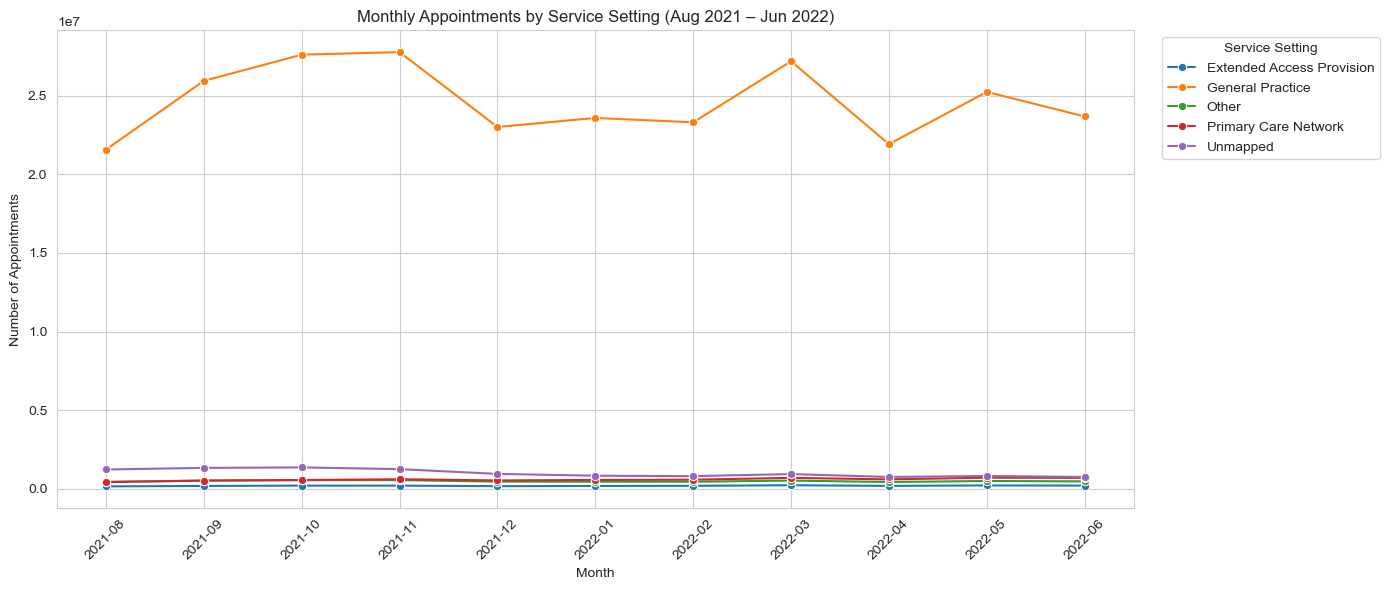

In [43]:
# create a Lineplot: monthly appointment volume, one line per service setting
plt.figure(figsize=(14, 6))
sns.lineplot(
    x='year_month_str',
    y='count_of_appointments',
    hue='service_setting',   # draws a separate coloured line per category
    data=nc_ss,
    marker='o',
    errorbar=None             
                               
)
plt.title('Monthly Appointments by Service Setting (Aug 2021 – Jun 2022)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')  # legend outside plot area to avoid overlapping lines
plt.tight_layout()
plt.show()

**Finding:** General Practice's monthly trend shows a clear rise, then fall pattern rather than a flat 
line: it climbs steadily from August 2021 to a peak around October–November 
2021, consistent with the Activity 3 (Q3) finding that these two months 
had the highest total appointment volume. It then drops sharply in December 2021, which lines up with the earlier hypothesis that reduced clinic availability over the holiday period, not falling demand, drove that dip, since General Practice alone 
accounts for most of the overall monthly total.

The remaining five service settings are nearly indistinguishable from each other and from 
zero on this chart, because General Practice's scale (tens of millions) dwarfs theirs 
(hundreds of thousands). The chart correctly shows that General Practice's volume is overwhelming, but it cannot be used to 
compare trends among the smaller service settings.

### 1b. Context types

In [42]:
# group by context_type
# Storing as a separate DataFrame (nc_ct)
nc_ct = (
    nc.groupby(['year_month_str', 'context_type'])['count_of_appointments']
    .sum()
    .reset_index()
)

nc_ct.head()

,year_month_str,context_type,count_of_appointments
0,2021-08,Care Related Encounter,20255235
1,2021-08,Inconsistent Mapping,2363093
2,2021-08,Unmapped,1233843
3,2021-09,Care Related Encounter,24404251
4,2021-09,Inconsistent Mapping,2782135


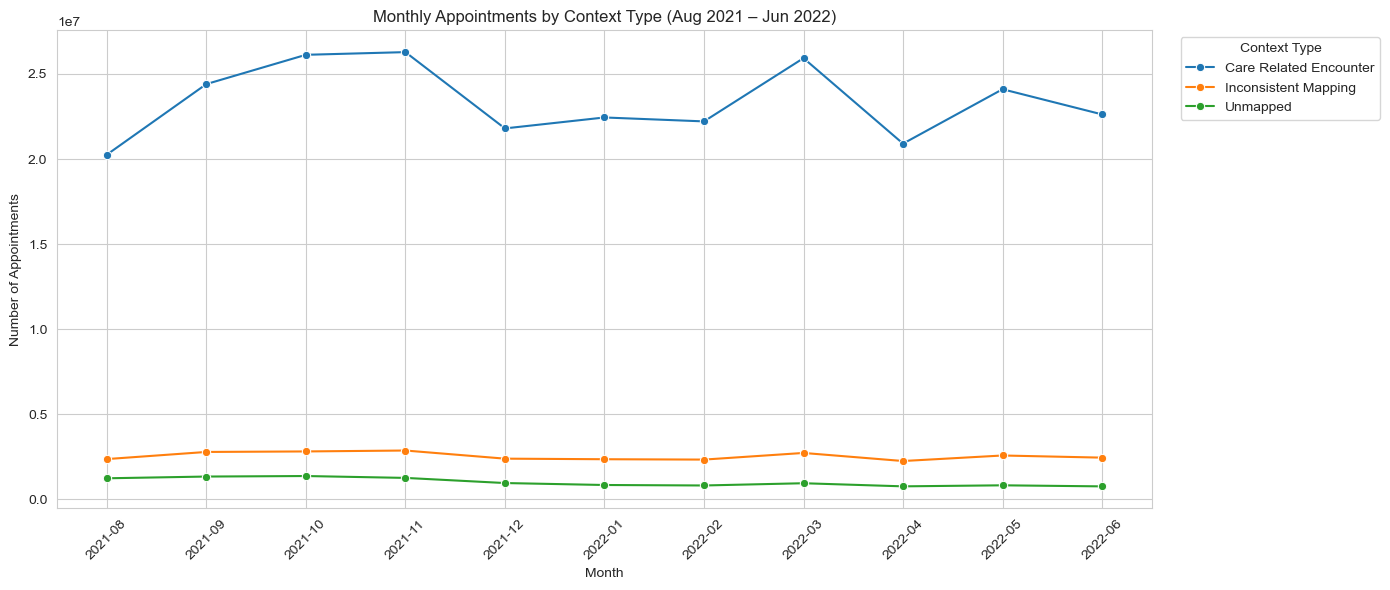

In [44]:
# create a lineplot

plt.figure(figsize=(14, 6))
sns.lineplot(
    x='year_month_str',
    y='count_of_appointments',
    hue='context_type',
    data=nc_ct,
    marker='o',
    errorbar=None
)
plt.title('Monthly Appointments by Context Type (Aug 2021 – Jun 2022)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Context Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Finding:** "Care Related Encounter" is by far the dominant context type, compared to 
"Inconsistent Mapping" and "Unmapped." 

The "Care Related Encounter" line follows the same monthly shape already identified in the 
service setting and Activity 3 (Q3) analysis: a rise from August 2021 to a peak spanning 
October - November 2021, a sharp drop in December 2021, a partial recovery through January - February 2022, a second peak in March 2022, and a gradual decline into April - June 2022. Since this context type accounts for 
the large majority of monthly volume, it's effectively driving the overall monthly trend 
seen across the whole dataset.

### 1c. National categories

In [52]:
# group by context_type
# Storing as a separate DataFrame (nc_nc)

nc_nc = (
    nc.groupby(['year_month_str', 'national_category'])['count_of_appointments']
    .sum()
    .reset_index()
)

nc_nc.head()

,year_month_str,national_category,count_of_appointments
0,2021-08,Care Home Needs Assessment & Personalised Care...,29676
1,2021-08,Care Home Visit,47583
2,2021-08,Clinical Triage,3704207
3,2021-08,General Consultation Acute,4280920
4,2021-08,General Consultation Routine,7756045


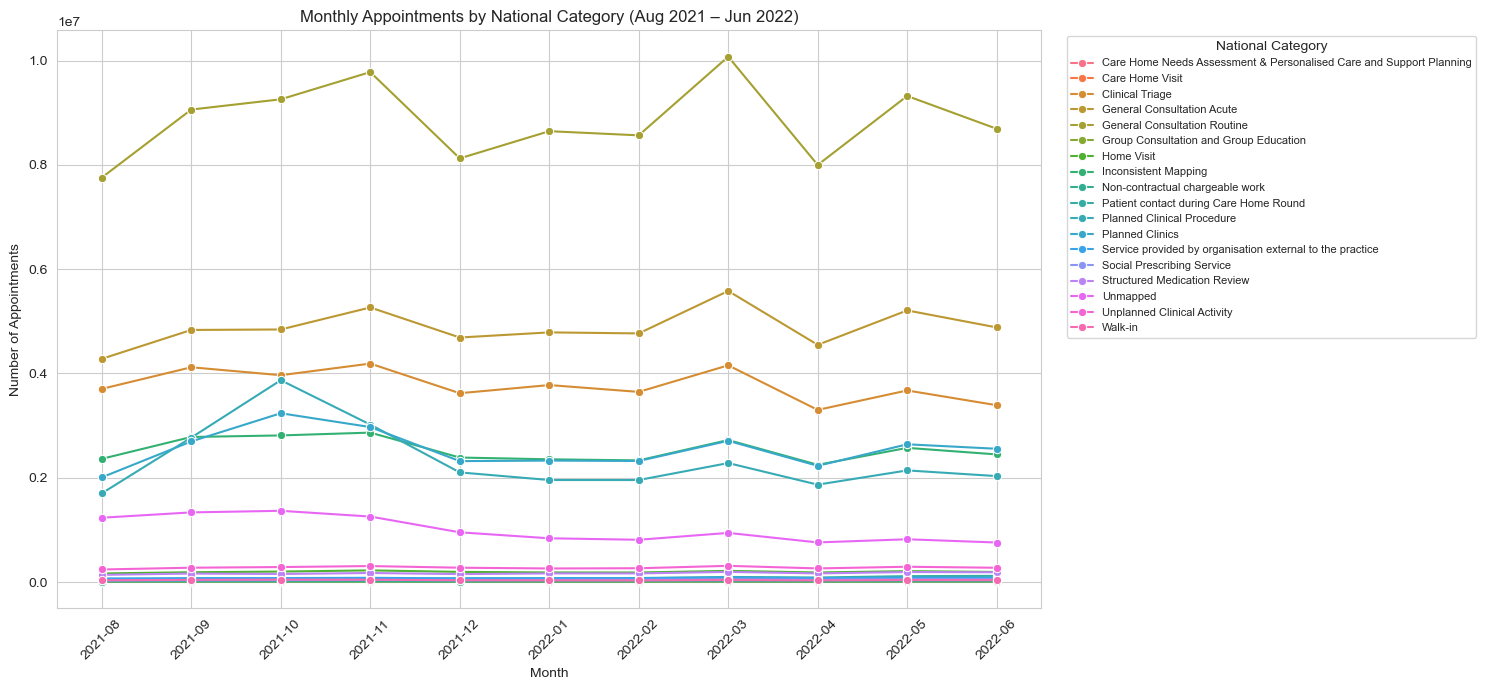

In [53]:
# create a lineplot

plt.figure(figsize=(15, 7))
sns.lineplot(
    x='year_month_str',
    y='count_of_appointments',
    hue='national_category',
    data=nc_nc,
    marker='o',
    errorbar=None
)
plt.title('Monthly Appointments by National Category (Aug 2021 – Jun 2022)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='National Category', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

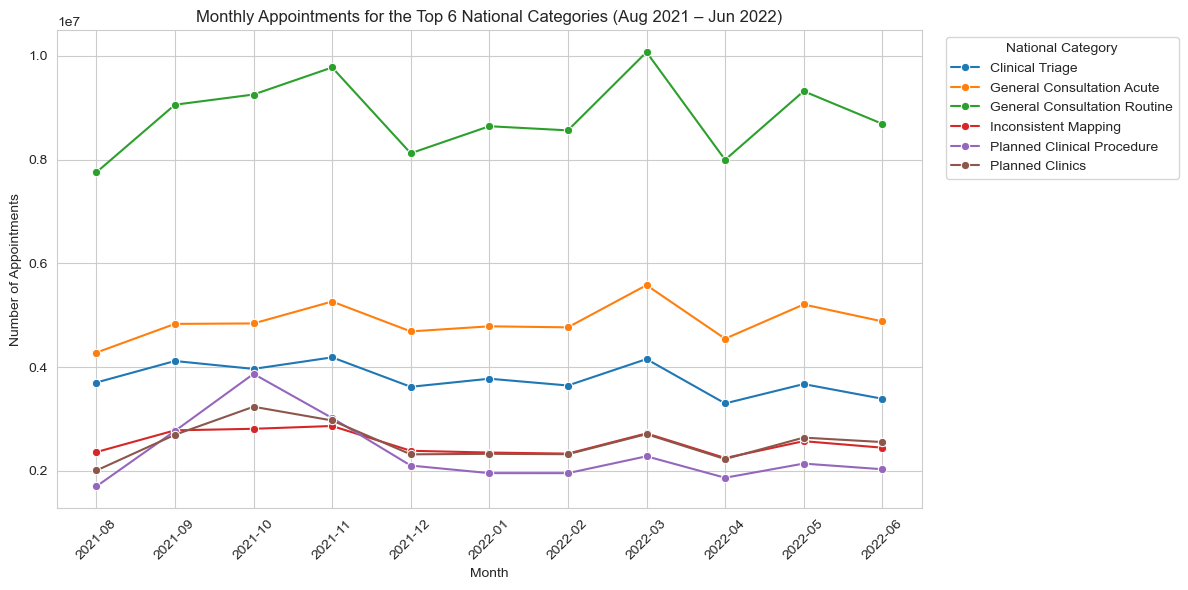

In [54]:
# Identify the top 6 national categories by total appointment volume
top_categories = (
    nc_nc.groupby('national_category')['count_of_appointments']
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index
)

# Filter the dataframe to include only the top 6 categories
nc_nc_top6 = nc_nc[nc_nc['national_category'].isin(top_categories)]

# Plot the filtered data
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=nc_nc_top6,
    x='year_month_str',
    y='count_of_appointments',
    hue='national_category',
    marker='o',
    errorbar=None
)

plt.title('Monthly Appointments for the Top 6 National Categories (Aug 2021 – Jun 2022)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='National Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

This lineplot shows the monthly appointment trends for the six national categories with the highest overall appointment volumes between August 2021 and June 2022. Restricting the visualisation to the highest-volume categories improves readability and allows clearer comparison of the key service areas driving appointment activity.

### Objective 2 - Appointments by service setting, per season

In [56]:
# group by service setting with a day-level aggregation

nc_ss_day = (
    nc.groupby(['appointment_date', 'service_setting'])['count_of_appointments']
    .sum()
    .reset_index()
)

nc_ss_day.head()

,appointment_date,service_setting,count_of_appointments
0,2021-08-01,Extended Access Provision,438
1,2021-08-01,General Practice,3411
2,2021-08-01,Other,401
3,2021-08-01,Primary Care Network,323
4,2021-08-01,Unmapped,1054


### 2a. Summer (June - August 2021)

In [57]:
# Filter for summer date range
# only August 2021 data will actually appear here, since nc starts 2021-08-01
# June and July 2021 are absent from the source data, and not filtered out by mistake

summer_mask = (nc_ss_day['appointment_date'] >= '2021-06-01') & (nc_ss_day['appointment_date'] <= '2021-08-31')
nc_ss_summer = nc_ss_day[summer_mask]

print(f"Date range actually present in summer subset:\
{nc_ss_summer['appointment_date'].min()} to {nc_ss_summer['appointment_date'].max()}")

Date range actually present in summer subset:2021-08-01 00:00:00 to 2021-08-31 00:00:00


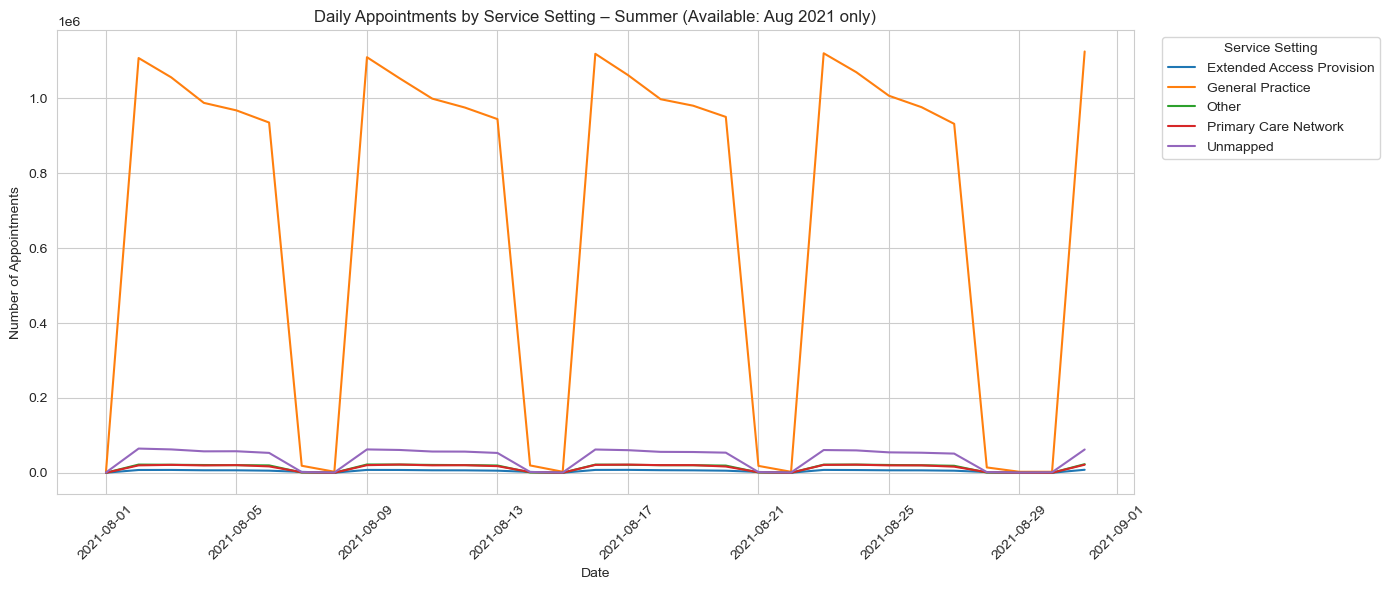

In [58]:
# create a lineplot

plt.figure(figsize=(14, 6))
sns.lineplot(
    x='appointment_date',
    y='count_of_appointments',
    hue='service_setting',
    data=nc_ss_summer,
    errorbar=None
)
plt.title('Daily Appointments by Service Setting – Summer (Available: Aug 2021 only)')
plt.xlabel('Date')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 2b. Autumn (September - November 2021)

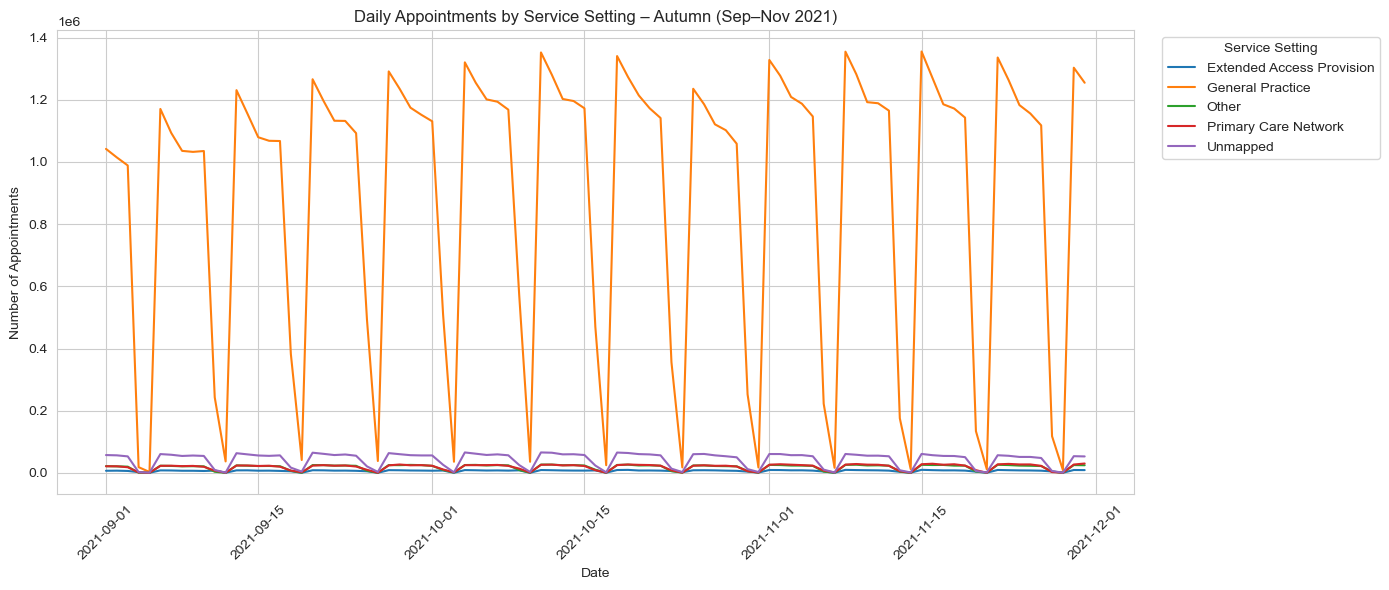

In [59]:
# filter for autumn dates
autumn_mask = (nc_ss_day['appointment_date'] >= '2021-09-01') & (nc_ss_day['appointment_date'] <= '2021-11-30')
nc_ss_autumn = nc_ss_day[autumn_mask]

# create a lineplot

plt.figure(figsize=(14, 6))
sns.lineplot(
    x='appointment_date',
    y='count_of_appointments',
    hue='service_setting',
    data=nc_ss_autumn,
    errorbar=None
)
plt.title('Daily Appointments by Service Setting – Autumn (Sep–Nov 2021)')
plt.xlabel('Date')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 2c. Winter (December 2021 – February 2022)

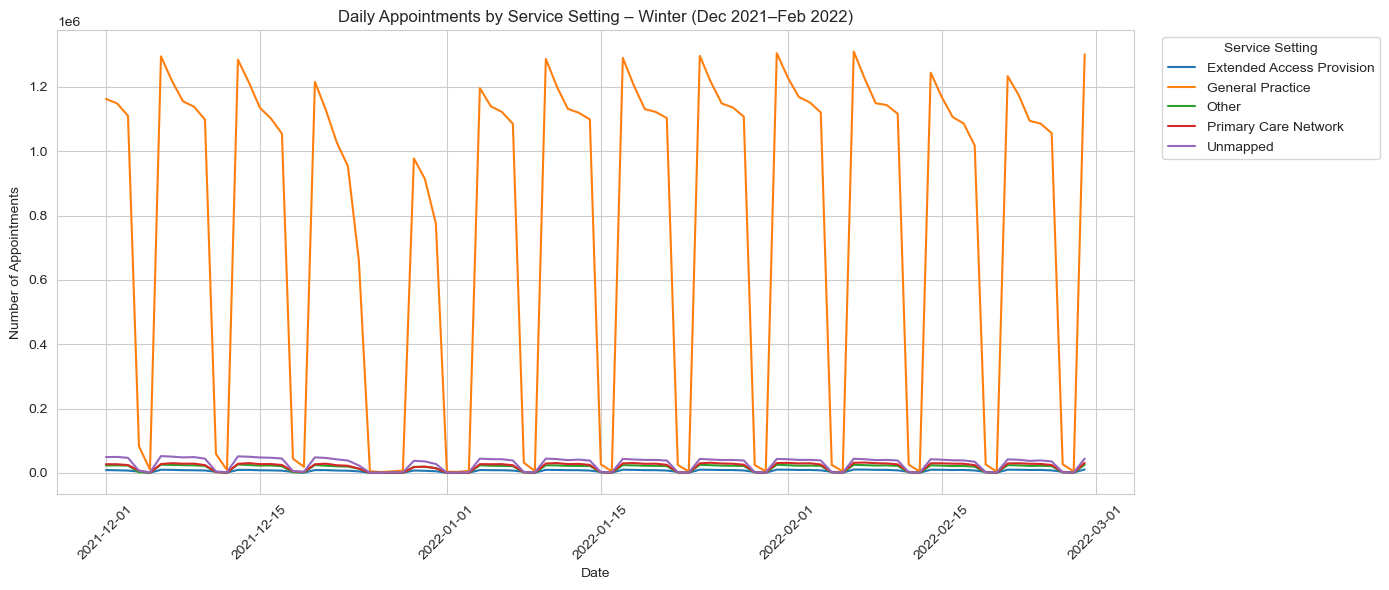

In [60]:
# filter for winter days
winter_mask = (nc_ss_day['appointment_date'] >= '2021-12-01') & (nc_ss_day['appointment_date'] <= '2022-02-28')
nc_ss_winter = nc_ss_day[winter_mask]

# create a lineplot

plt.figure(figsize=(14, 6))
sns.lineplot(
    x='appointment_date',
    y='count_of_appointments',
    hue='service_setting',
    data=nc_ss_winter,
    errorbar=None
)
plt.title('Daily Appointments by Service Setting – Winter (Dec 2021–Feb 2022)')
plt.xlabel('Date')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 2d. Spring (March – May 2022)

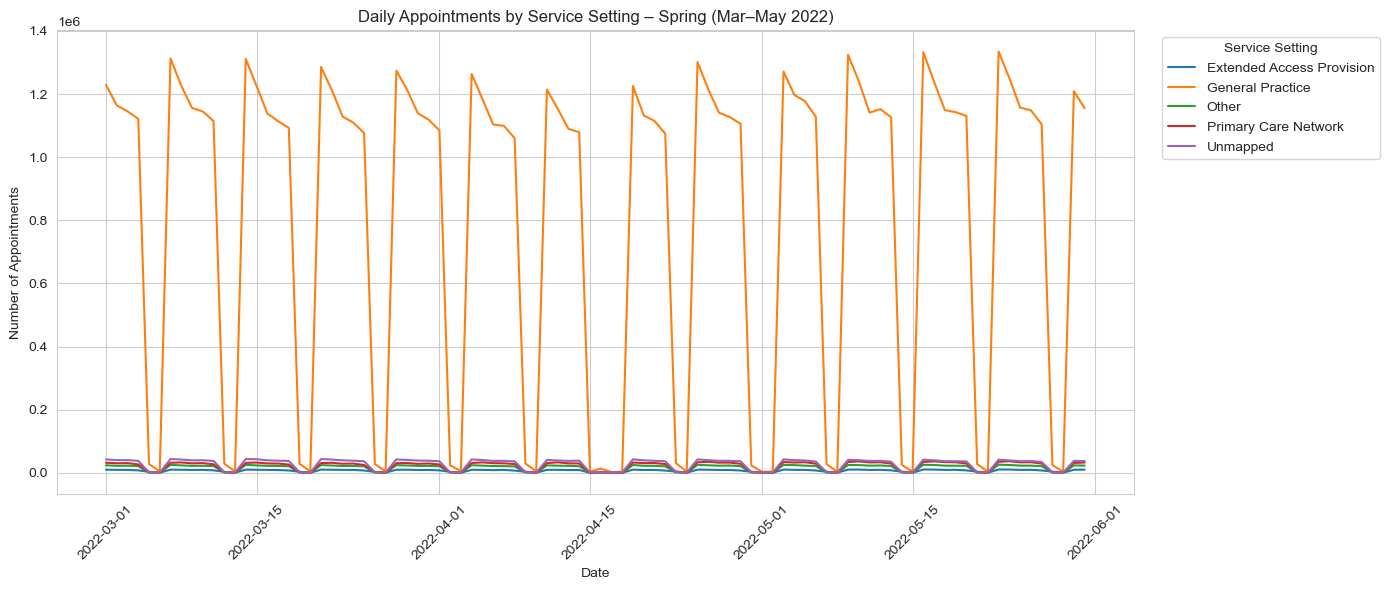

In [61]:
# filter for spring days

spring_mask = (nc_ss_day['appointment_date'] >= '2022-03-01') & (nc_ss_day['appointment_date'] <= '2022-05-31')
nc_ss_spring = nc_ss_day[spring_mask]

# create a lineplot 

plt.figure(figsize=(14, 6))
sns.lineplot(
    x='appointment_date',
    y='count_of_appointments',
    hue='service_setting',
    data=nc_ss_spring,
    errorbar=None
)
plt.title('Daily Appointments by Service Setting – Spring (Mar–May 2022)')
plt.xlabel('Date')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Assignment Activity 5: Analysing NHS-related X data

In [63]:
import pandas as pd
import seaborn as sns

# Set figure size.
sns.set(rc={'figure.figsize':(15, 12)})

# Set the plot style as white.
sns.set_style('white')

# Maximum column width to display
pd.options.display.max_colwidth = 200

tweets = pd.read_csv('tweets.csv')
tweets.head()

,tweet_id,tweet_full_text,tweet_entities,tweet_entities_hashtags,tweet_metadata,tweet_retweet_count,tweet_favorite_count,tweet_favorited,tweet_retweeted,tweet_lang
0,1567629223795527681,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...","{'hashtags': [{'text': 'Healthcare', 'indices': [253, 264]}], 'symbols': [], 'user_mentions': [], 'urls': [{'url': 'https://t.co/yw0cstfmSI', 'expanded_url': 'https://bit.ly/3BiSKbs', 'display_url...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en
1,1567582846612553728,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…,"{'hashtags': [{'text': 'PremiseHealth', 'indices': [94, 108]}, {'text': 'hiring', 'indices': [127, 134]}], 'symbols': [], 'user_mentions': [{'screen_name': 'AndreaGrammer', 'name': 'Andrea Grammer...","#PremiseHealth, #hiring","{'iso_language_code': 'en', 'result_type': 'recent'}",2,0,False,False,en
2,1567582787070304256,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…,"{'hashtags': [{'text': 'Healthcare', 'indices': [70, 81]}], 'symbols': [], 'user_mentions': [{'screen_name': 'OntarioGreens', 'name': 'Green Party of Ontario', 'id': 37115912, 'id_str': '37115912'...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",39,0,False,False,en
3,1567582767625428992,RT @modrnhealthcr: 🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data…,"{'hashtags': [{'text': 'NEW', 'indices': [20, 24]}], 'symbols': [], 'user_mentions': [{'screen_name': 'modrnhealthcr', 'name': 'Modern Healthcare', 'id': 18935711, 'id_str': '18935711', 'indices':...",#NEW,"{'iso_language_code': 'en', 'result_type': 'recent'}",5,0,False,False,en
4,1567582720460570625,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di...","{'hashtags': [{'text': 'blogs', 'indices': [184, 190]}, {'text': 'digitaltransformation', 'indices': [191, 213]}, {'text': 'cybersecurity', 'indices': [214, 228]}, {'text': 'accounting', 'indices'...","#blogs, #digitaltransformation, #cybersecurity, #accounting, #finance, #healthcare","{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en


In [66]:
tweets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1174 entries, 0 to 1173
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   tweet_id                 1174 non-null   int64 
 1   tweet_full_text          1174 non-null   object
 2   tweet_entities           1174 non-null   object
 3   tweet_entities_hashtags  1007 non-null   object
 4   tweet_metadata           1174 non-null   object
 5   tweet_retweet_count      1174 non-null   int64 
 6   tweet_favorite_count     1174 non-null   int64 
 7   tweet_favorited          1174 non-null   bool  
 8   tweet_retweeted          1174 non-null   bool  
 9   tweet_lang               1174 non-null   object
dtypes: bool(2), int64(3), object(5)
memory usage: 75.8+ KB


In [65]:
print(tweets['tweet_retweet_count'].value_counts())
print()
print(tweets['tweet_favorite_count'].value_counts())

tweet_retweet_count
0      526
1      215
2      114
3       70
5       35
4       27
7       18
12      16
8       15
73      14
9       13
6       12
208     12
35      10
37       6
11       6
10       5
53       5
44       4
150      4
63       4
76       3
85       3
41       3
62       3
207      3
68       3
78       2
23       2
24       2
72       2
16       2
13       1
49       1
48       1
15       1
107      1
14       1
79       1
20       1
39       1
19       1
303      1
57       1
40       1
54       1
169      1
Name: count, dtype: int64

tweet_favorite_count
0     1027
1       91
2       16
3       13
4        7
5        5
6        2
17       1
12       1
10       1
8        1
13       1
11       1
7        1
20       1
28       1
14       1
18       1
9        1
42       1
Name: count, dtype: int64


## Would it be useful to look at these columns in more detail?

Based on `value_counts()`, both `tweet_retweet_count` and `tweet_favorite_count` are dominated by 0, meaning that most tweets in this sample have never been retweeted or 
favourited, with only a small number of outliers reaching meaningful engagement.

For the specific objective of identifying trending hashtags, these two columns are not 
particularly useful. Engagement counts measure how popular an individual tweet was, not 
how frequently a topic or hashtag appears across the dataset; a hashtag can be extremely 
common (appearing in hundreds of tweets) while none of those individual tweets are 
individually popular. Since the goal here is trend/topic identification, not influencer or 
virality analysis, hashtag frequency is the more relevant signal.

However, these columns could become useful in a separate analysis, for example, 
to identify which specific healthcare topics generated the most public engagement, not just 
the most volume, which would be a different question 
for the NHS: "what topics do people care enough about to actively share," rather than just 
"what topics are being tweeted about most often."

In [67]:
# Create a new DataFrame with only the text values, since hashtag extraction only needs
# the tweet content, not the metadata columns

tweets_text = tweets[['tweet_full_text']].copy()

# View the new DataFrame
tweets_text.head()

,tweet_full_text
0,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be..."
1,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…
2,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…
3,RT @modrnhealthcr: 🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data…
4,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di..."


In [68]:
# Create an empty list to store every hashtag found across all tweets
tags = []

# Loop through each tweet's text
for message in tweets_text['tweet_full_text']:
    # Split the tweet into individual words on whitespace
    words = message.split()
    # Keep only the words that start with '#' - i.e. the hashtags
    # This is a simple, direct way to extract hashtags without needing regex,
    # though it will also catch a trailing punctuation mark attached to a hashtag
    # (e.g. "#NHS." would be kept as-is) - worth noting as a minor limitation
    hashtags_in_message = [word for word in words if word.startswith('#')]
    # Add all hashtags found in this tweet to the master list
    tags.extend(hashtags_in_message)

# tags now contains every hashtag occurrence across the whole dataset, including duplicates
print(f"Total hashtag occurrences found: {len(tags)}")

Total hashtag occurrences found: 4327


In [69]:
# Create a pandas Series counting how many times each hashtag appears
# pd.Series(tags).value_counts() counts occurrences of each unique value in the list,

tag_counts = pd.Series(tags).value_counts()

# Display the first 30 records - the 30 most frequent hashtags
tag_counts.head(30)

#healthcare                    549
#Healthcare                    190
#health                         66
#HealthCare                     46
#AI                             43
#medicine                       42
#job                            38
#medical                        30
#strategy                       30
#pharma                         25
#digitalhealth                  25
#biotech                        25
#MedTwitter                     25
#competitiveintelligence        24
#pharmaceutical                 24
#marketing                      24
#MedEd                          23
#TipsForNewDocs                 21
#vaccine                        18
#Health                         18
#MachineLearning                17
#coronavirus                    16
#WomenInMedicine                16
#competitivemarketing           16
#hiring                         15
#healthcare.                    15
#telehealth                     14
#medicare                       14
#DoctorofVeterinaryM

### Identify the top trending hashtags with a visualisation

In [71]:
# Convert the Series into a DataFrame

data = tag_counts.reset_index()

# Rename the columns
data.columns = ['word', 'count']

data.head()

,word,count
0,#healthcare,549
1,#Healthcare,190
2,#health,66
3,#HealthCare,46
4,#AI,43


In [72]:
# Confirm count is an integer type for correct numeric plotting

data['count'] = data['count'].astype(int)

print(data.dtypes)
data.head()

word     object
count     int64
dtype: object


,word,count
0,#healthcare,549
1,#Healthcare,190
2,#health,66
3,#HealthCare,46
4,#AI,43


In [73]:
# Display records where the count is larger than 10.
data_over_10 = data[data['count'] > 10].sort_values('count', ascending=False)

print(f"Number of hashtags used more than 10 times: {len(data_over_10)}")

Number of hashtags used more than 10 times: 37


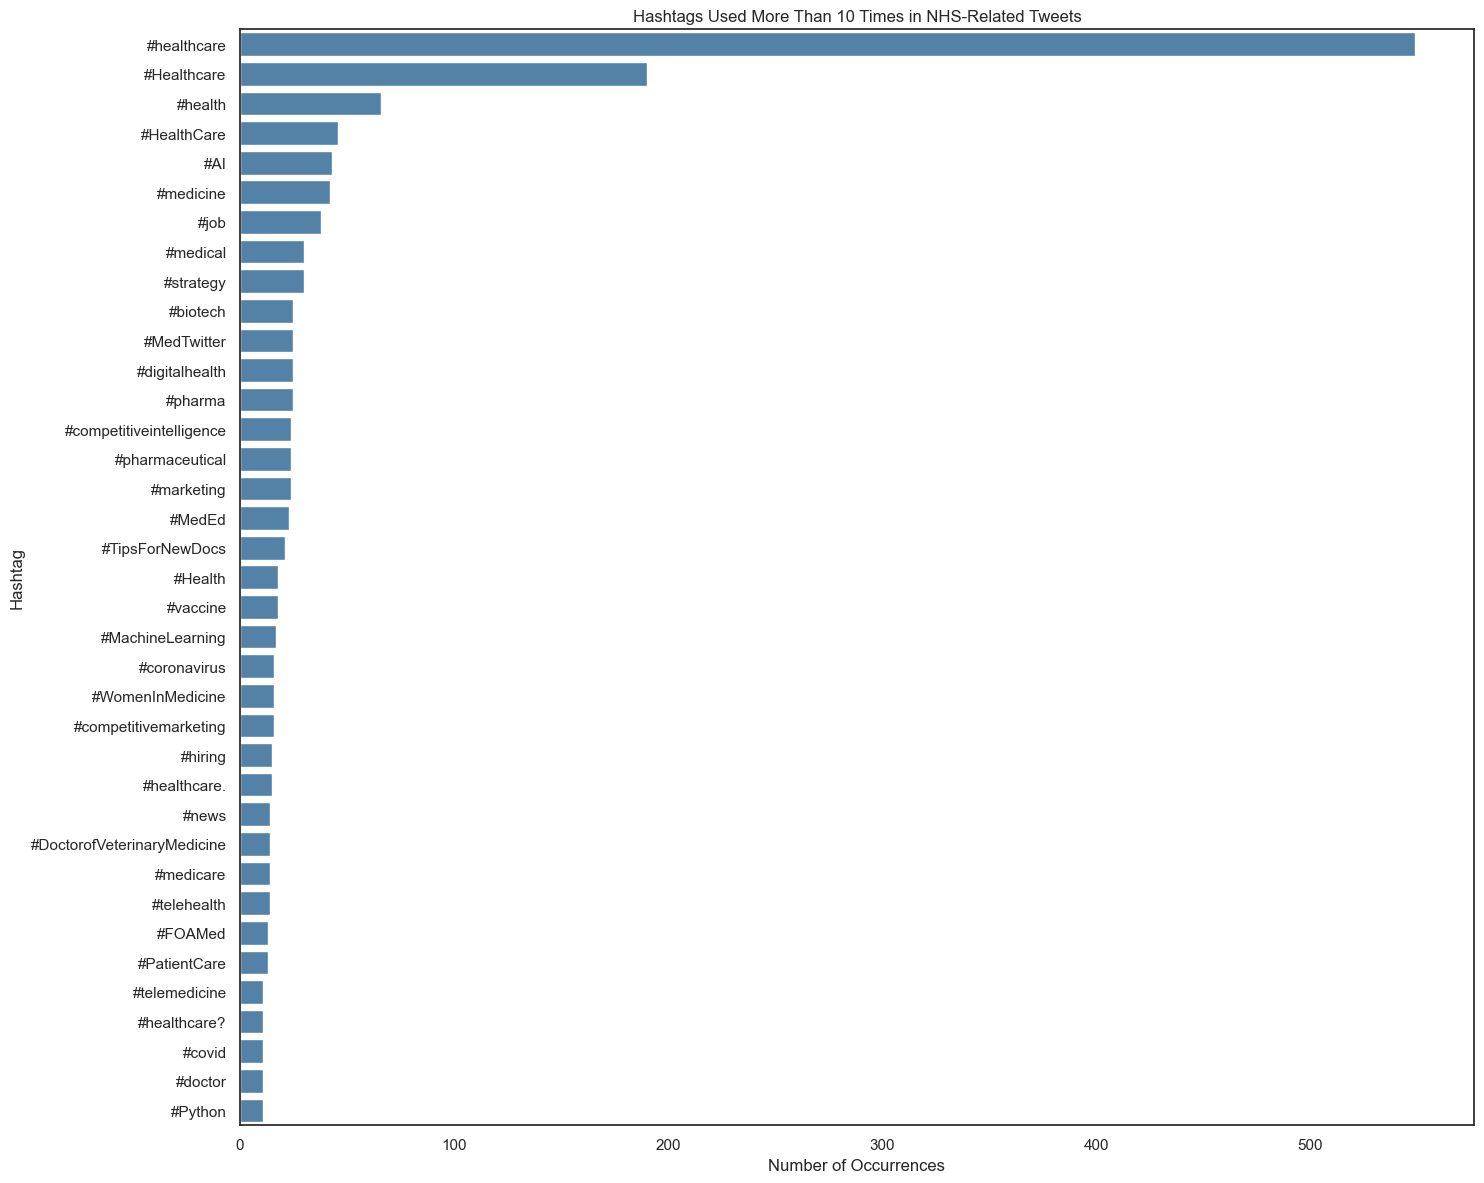

In [75]:
# create a barplot

plt.figure(figsize=(15, 12))
sns.barplot(x='count', y='word', data=data_over_10, color='steelblue')
plt.title('Hashtags Used More Than 10 Times in NHS-Related Tweets')
plt.xlabel('Number of Occurrences')
plt.ylabel('Hashtag')
plt.tight_layout()
plt.show()

In [77]:
# Remove the generic overrepresented hashtags like "healthcare"/"health" 
# These don't represent distinct topics, just the same dominant tag counted several times.

overrepresented = [
    '#Healthcare', '#health', '#HealthCare', '#Health',
    '#healthcare.', '#healthcare?'
]

# Filter out overrepresented hashtags, keeping every other hashtag with more than 10 occurrences
data_filtered = data_over_10[~data_over_10['word'].isin(overrepresented)]

print(f"Hashtags remaining after filtering: {len(data_filtered)}")
data_filtered.head(10)

Hashtags remaining after filtering: 31


,word,count
0,#healthcare,549
4,#AI,43
5,#medicine,42
6,#job,38
7,#medical,30
8,#strategy,30
11,#biotech,25
12,#MedTwitter,25
10,#digitalhealth,25
9,#pharma,25


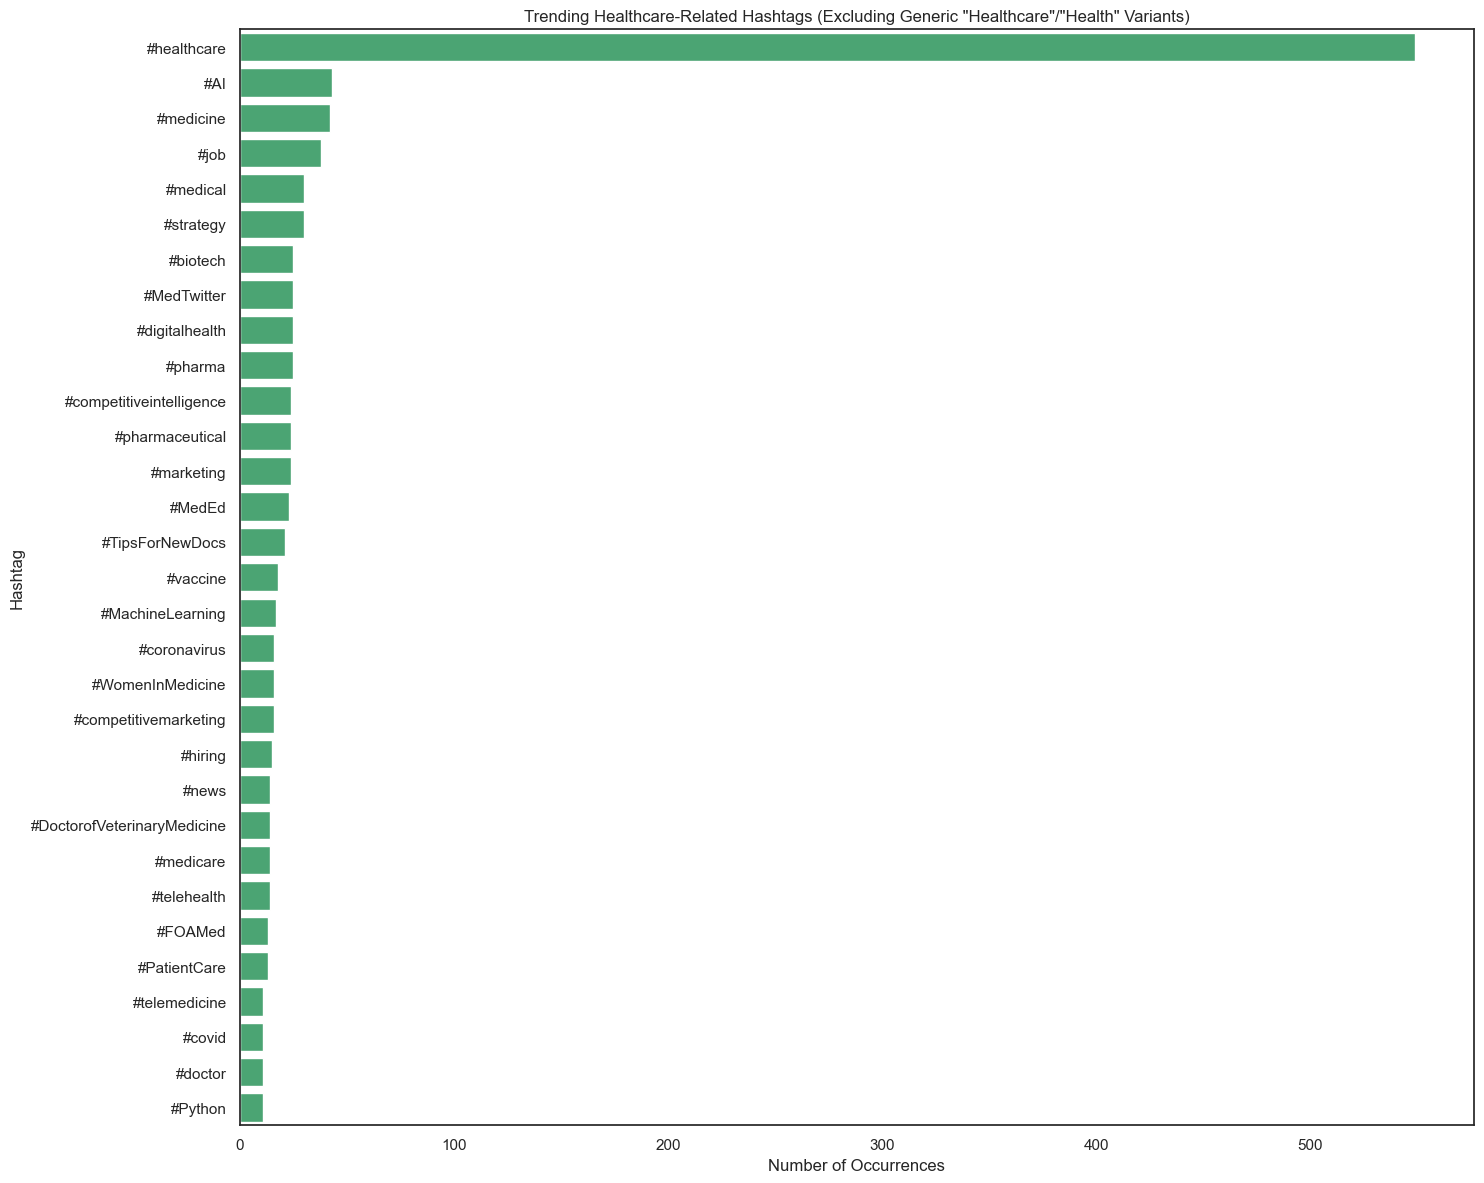

In [78]:
# create a barplot of filtered hashtags

plt.figure(figsize=(15, 12))
sns.barplot(x='count', y='word', data=data_filtered, color='mediumseagreen')
plt.title('Trending Healthcare-Related Hashtags (Excluding Generic "Healthcare"/"Health" Variants)')
plt.xlabel('Number of Occurrences')
plt.ylabel('Hashtag')
plt.tight_layout()
plt.show()

This activity demonstrated a basic but genuinely informative workflow for extracting signal 
from unstructured social media text: splitting tweet text into words, filtering for hashtags, 
counting frequency, and visualising the result.

To improve the visualisation for stakeholder communication, the process moved from an 
unfiltered "count > 10" chart (still dominated by generic terms) to a filtered version 
removing overrepresented generic hashtags, and finally to a colour-graded version that 
visually reinforces relative frequency at a glance, progressively making the chart easier 
for a non-technical audience to interpret quickly.

# Assignment activity 6

In [80]:
# view the appointments_regional DF
ar.head()

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments,year_month
0,E54000034,2020-01-01,Attended,GP,Face-to-Face,1 Day,8107,2020-01
1,E54000034,2020-01-01,Attended,GP,Face-to-Face,15 to 21 Days,6791,2020-01
2,E54000034,2020-01-01,Attended,GP,Face-to-Face,2 to 7 Days,20686,2020-01
3,E54000034,2020-01-01,Attended,GP,Face-to-Face,22 to 28 Days,4268,2020-01
4,E54000034,2020-01-01,Attended,GP,Face-to-Face,8 to 14 Days,11971,2020-01


In [110]:
# Convert appointment_month to datetime so min()/max() will reflect true chronological order,

ar['appointment_month'] = pd.to_datetime(ar['appointment_month'], format='%Y-%m')

# Print the minimum and maximum dates
print(f"ar date range: {ar['appointment_month'].min()} to {ar['appointment_month'].max()}")

ar date range: 2021-08-01 00:00:00 to 2022-06-01 00:00:00


In [82]:
# Filter the data set to only look at data from 2021-08 onwards.

ar = ar[ar['appointment_month'] >= '2021-08-01'].copy()

# View the filtered DataFrame
ar.head()

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments,year_month
3652,E54000034,2021-08-01,Attended,GP,Face-to-Face,1 Day,6553,2021-08
3653,E54000034,2021-08-01,Attended,GP,Face-to-Face,15 to 21 Days,2390,2021-08
3654,E54000034,2021-08-01,Attended,GP,Face-to-Face,2 to 7 Days,10547,2021-08
3655,E54000034,2021-08-01,Attended,GP,Face-to-Face,22 to 28 Days,937,2021-08
3656,E54000034,2021-08-01,Attended,GP,Face-to-Face,8 to 14 Days,4961,2021-08


## **Question 1:** Should the NHS start looking at increasing staff levels? 

In [83]:
# Create an aggregated data set to review the different features together
ar_agg = (
    ar.groupby(['appointment_month', 'hcp_type', 'appointment_status',
                'appointment_mode', 'time_between_book_and_appointment'])
    ['count_of_appointments']
    .sum()
    .reset_index()
)

ar_agg.head()

,appointment_month,hcp_type,appointment_status,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,2021-08-01,GP,Attended,Face-to-Face,1 Day,507835
1,2021-08-01,GP,Attended,Face-to-Face,15 to 21 Days,194726
2,2021-08-01,GP,Attended,Face-to-Face,2 to 7 Days,959486
3,2021-08-01,GP,Attended,Face-to-Face,22 to 28 Days,102111
4,2021-08-01,GP,Attended,Face-to-Face,8 to 14 Days,398772


In [84]:
# Determine the total number of appointments per month
ar_df = (
    ar.groupby('appointment_month')['count_of_appointments']
    .sum()
    .reset_index()
)

# Add a utilisation column: monthly total / 30 = average daily appointments
# This is a simplification (not every month has exactly 30 days), but gives a consistent,
# comparable daily estimate across months for benchmarking against the NHS capacity figure

ar_df['utilisation'] = (ar_df['count_of_appointments'] / 30).round(1)

ar_df.head()

,appointment_month,count_of_appointments,utilisation
0,2021-08-01,23852171,795072.4
1,2021-09-01,28522501,950750.0
2,2021-10-01,30303834,1010127.8
3,2021-11-01,30405070,1013502.3
4,2021-12-01,25140776,838025.9


In [85]:
# Plot sum of count of monthly visits.
# Convert the appointment_month to string data type for ease of visualisation.

ar_agg['appointment_month'] = ar_agg['appointment_month'].astype(str)
ar_df['appointment_month'] = ar_df['appointment_month'].astype(str)

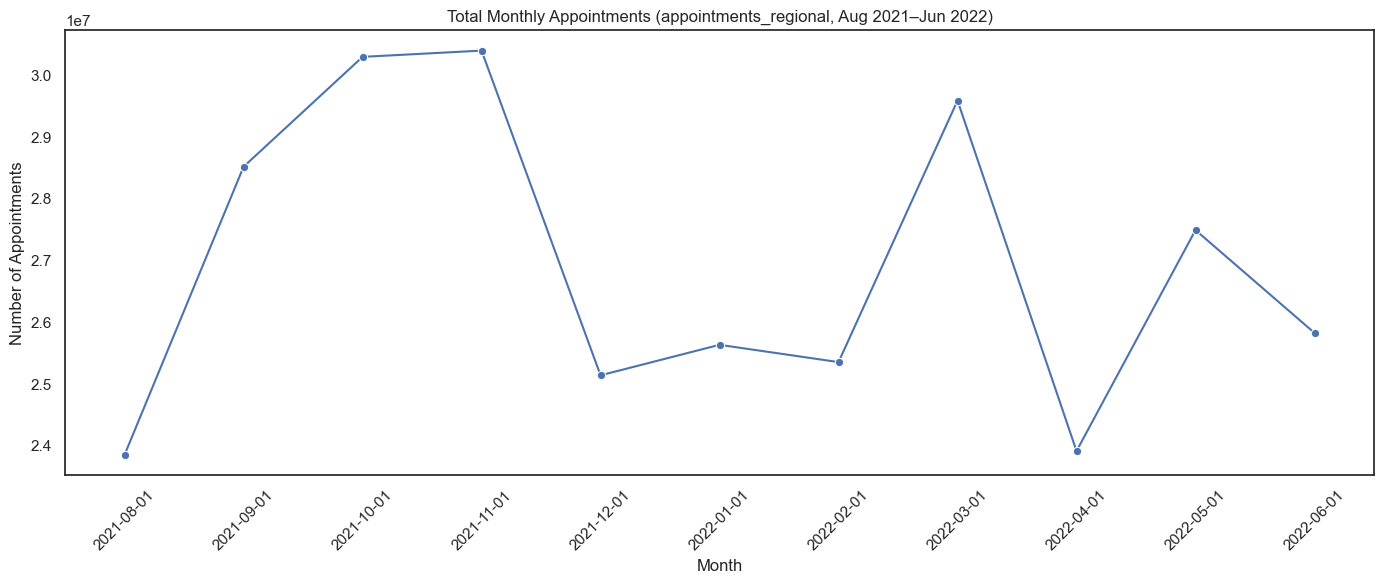

In [86]:
# Create a lineplot with Seaborn.

# Lineplot: total monthly appointment volume
plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='count_of_appointments', data=ar_df, marker='o', errorbar=None)
plt.title('Total Monthly Appointments (appointments_regional, Aug 2021–Jun 2022)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

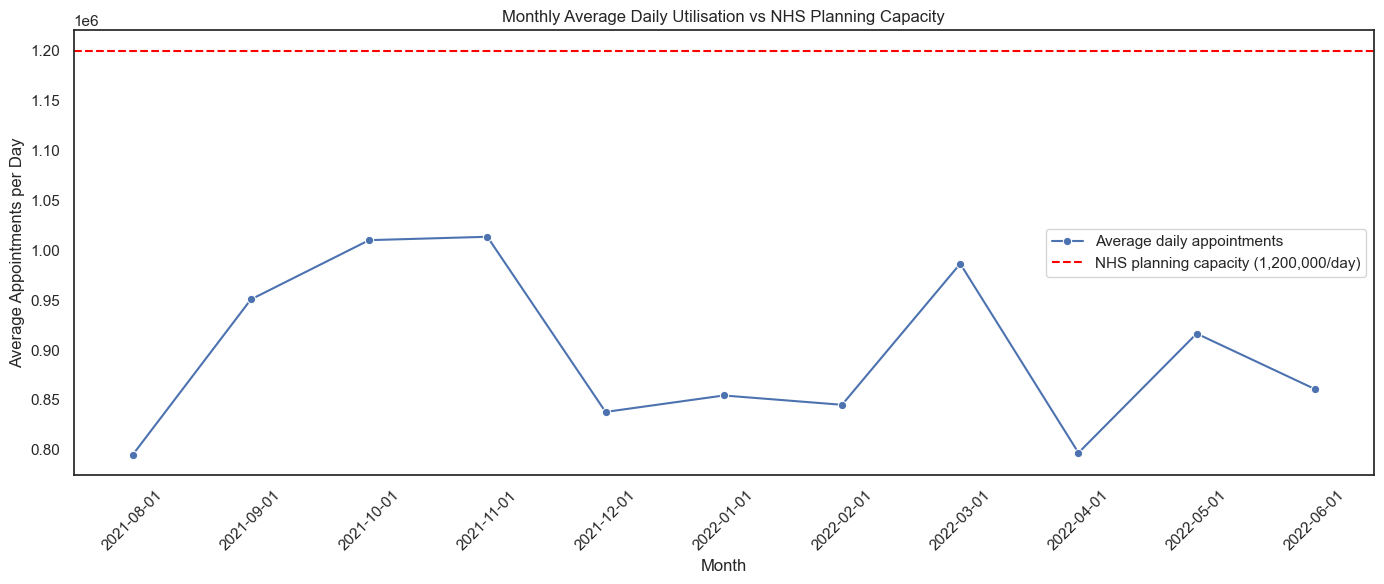

In [87]:
# Lineplot: monthly capacity utilisation vs the NHS-provided planning benchmark
plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='utilisation', data=ar_df, marker='o', errorbar=None, label='Average daily appointments')

# NHS planning benchmark: 1,200,000 appointments/day used as the maximum capacity guideline
plt.axhline(y=1200000, color='red', linestyle='--', label='NHS planning capacity (1,200,000/day)')

plt.title('Monthly Average Daily Utilisation vs NHS Planning Capacity')
plt.xlabel('Month')
plt.ylabel('Average Appointments per Day')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Findings:** On a monthly-average basis, this data does not show the system operating at or beyond 
its stated capacity at any point in the available period. If monthly average utilisation 
were the only evidence considered, it would suggest the NHS has consistent headroom, even 
during its busiest months (Oct–Nov 2021, Mar 2022), and would not on its own support a case 
for increasing staff levels.

## **Question 2:** How do the healthcare professional types differ over time?

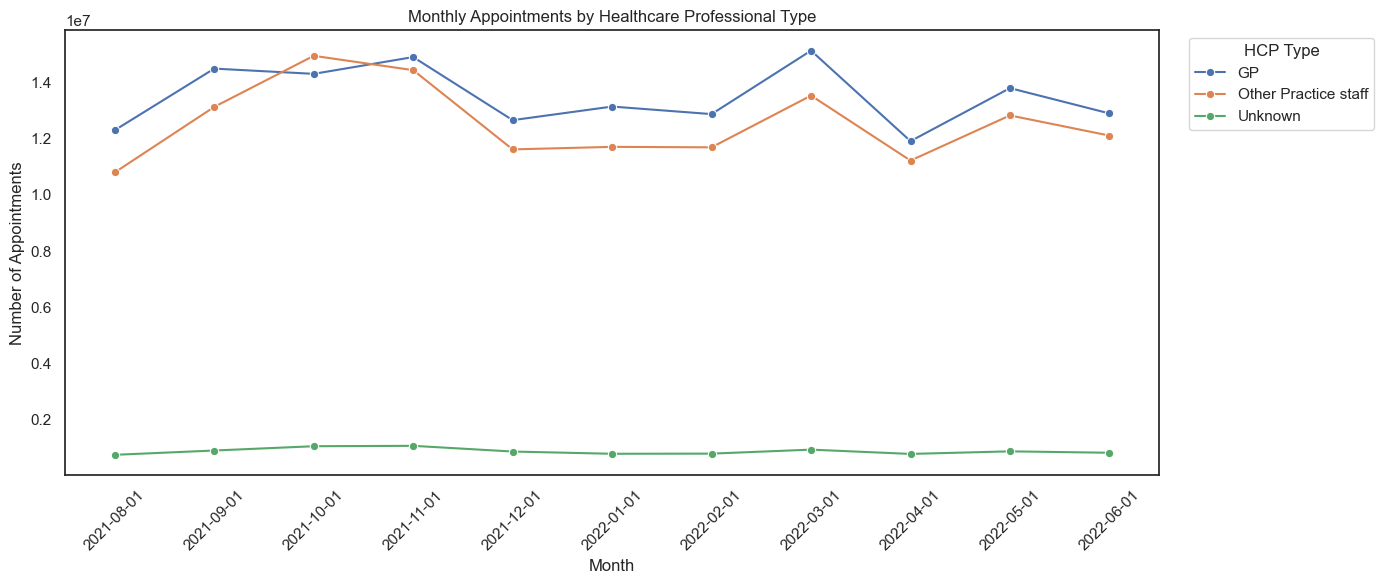

In [89]:
# Aggregate monthly appointments by hcp_type
ar_hcp = (
    ar.groupby(['appointment_month', 'hcp_type'])['count_of_appointments']
    .sum()
    .reset_index()
)
ar_hcp['appointment_month'] = ar_hcp['appointment_month'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='count_of_appointments', hue='hcp_type', data=ar_hcp, marker='o', errorbar=None)
plt.title('Monthly Appointments by Healthcare Professional Type')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='HCP Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

The line plot shows that GPs consistently account for the largest share of appointments throughout the observed period (Aug 2021 - Jun 2022). Their trend mirrors the overall volume pattern, with a clear rise around October - November, a dip in December, and a rebound in early spring (March).
Other Practice Staff maintain a smaller but gradually increasing share, suggesting a steady expansion in their role over time, possibly reflecting a shift toward more distributed care delivery within practices.
The Unknown category remains relatively stable, which highlights that a persistent portion of appointments cannot be confidently attributed to a specific professional type.

## **Question 3:** Are there significant changes in whether or not visits are attended?

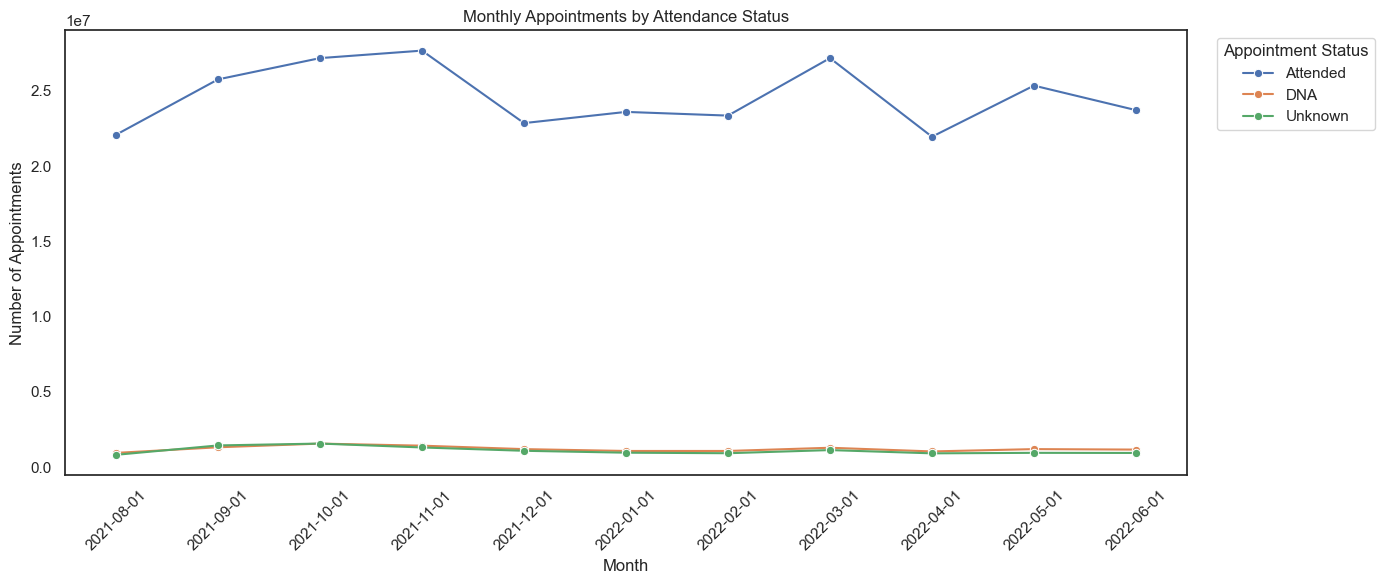

In [90]:
# Aggregate monthly appointments by appointment_status
ar_status = (
    ar.groupby(['appointment_month', 'appointment_status'])['count_of_appointments']
    .sum()
    .reset_index()
)
ar_status['appointment_month'] = ar_status['appointment_month'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='count_of_appointments', hue='appointment_status', data=ar_status, marker='o', errorbar=None)
plt.title('Monthly Appointments by Attendance Status')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Appointment Status', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

The line plot shows that Attended appointments dominate across all months, with a clear cyclical pattern, rising through September - October, dipping around December, and peaking again in March. 
DNA (Did Not Attend) and Unknown categories remain low and relatively stable, moving roughly in parallel with the Attended line. This suggests that the proportion of missed appointments stays consistent over time rather than fluctuating.

## **Question 4:** Are there changes in terms of appointment type and the busiest months?

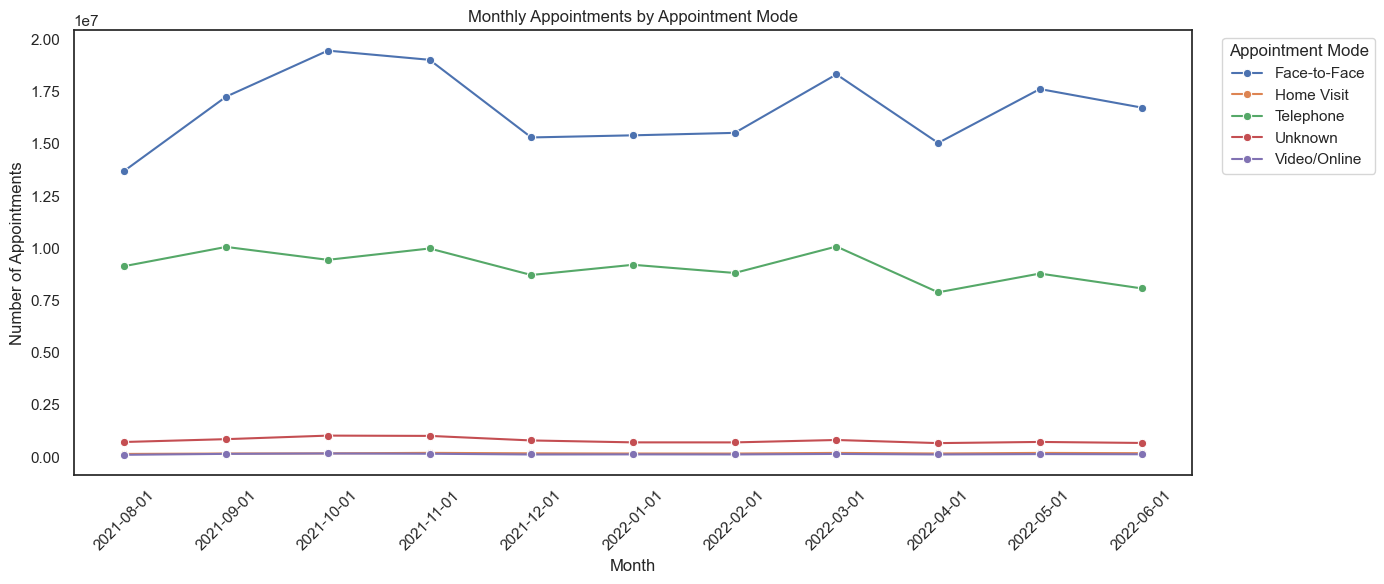

In [92]:
# Aggregate monthly appointments by appointment_mode
ar_mode = (
    ar.groupby(['appointment_month', 'appointment_mode'])['count_of_appointments']
    .sum()
    .reset_index()
)
ar_mode['appointment_month'] = ar_mode['appointment_month'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='count_of_appointments',
             hue='appointment_mode', data=ar_mode, marker='o', errorbar=None)
plt.title('Monthly Appointments by Appointment Mode')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Appointment Mode', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Finding:** " Face-to-Face appointment remains the dominant mode 
throughout. Remote modes decline overtime and this could reflect a return to in-person care as Covid-era remote consultation policies eased. The busiest months by mode align with the Oct-Nov and March peaks 
already identified. This shows that the peak is a genuine 
demand effect.

## **Question 5:** Are there any trends in time between booking and appointment?

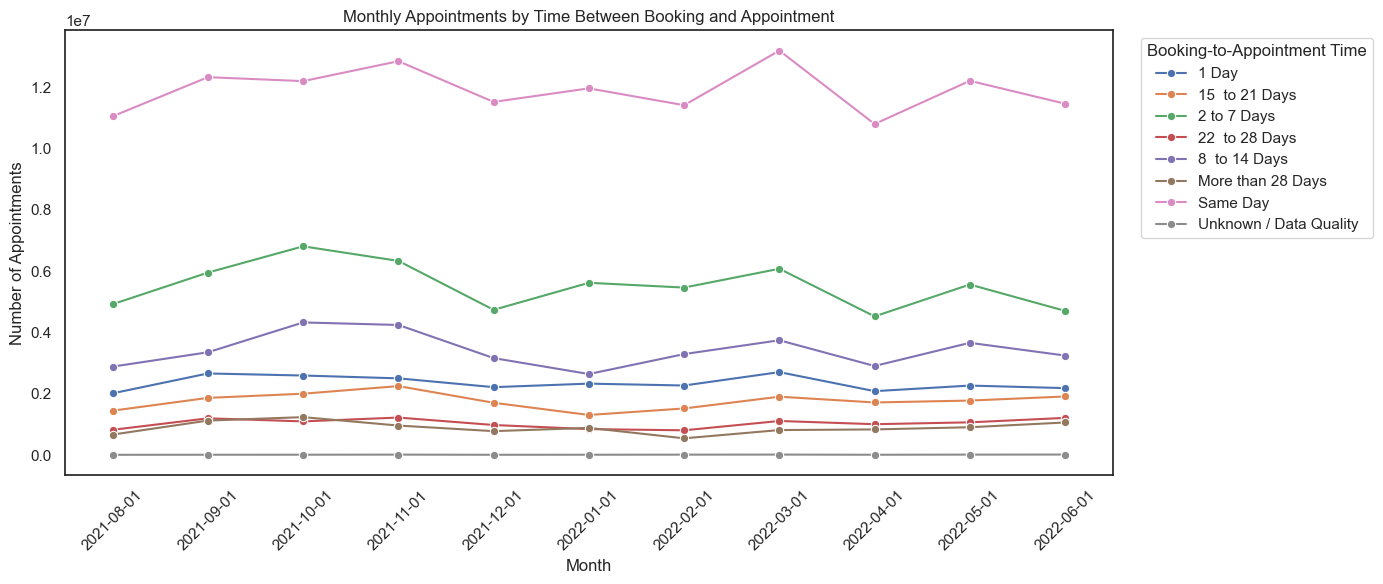

In [93]:
# Aggregate monthly appointments by time_between_book_and_appointment
ar_booking = (
    ar.groupby(['appointment_month', 'time_between_book_and_appointment'])['count_of_appointments']
    .sum()
    .reset_index()
)
ar_booking['appointment_month'] = ar_booking['appointment_month'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='count_of_appointments', hue='time_between_book_and_appointment', data=ar_booking, marker='o', errorbar=None)
plt.title('Monthly Appointments by Time Between Booking and Appointment')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Booking-to-Appointment Time', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Finding:** The same day booking band consistently accounts for 
the largest share of appointments, suggesting most GP appointments are booked very close to 
the appointment date itself, rather than scheduled far in advance. Some of the longer booking 
windows also grew during peak months like March. This is a direct, quantifiable 
signal of capacity strain. Longer waits may also be contributing to missed 
appointments.

## **Question 6:** How do the various service settings compare?

In [94]:
# view national_categories DF

nc.head()

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,year,month,year_month,year_month_str
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,2021,8,2021-08,2021-08
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,2021,8,2021-08,2021-08
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08,2021,8,2021-08,2021-08
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08,2021,8,2021-08,2021-08
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08,2021,8,2021-08,2021-08


In [95]:
# Group by month of appointment and service setting, summing appointment counts
nc_month_setting = (
    nc.groupby(['year_month', 'service_setting'])['count_of_appointments']
    .sum()
    .reset_index()
)

# Convert year_month to string for plotting
nc_month_setting['year_month'] = nc_month_setting['year_month'].astype(str)

nc_month_setting.head()

,year_month,service_setting,count_of_appointments
0,2021-08,Extended Access Provision,160927
1,2021-08,General Practice,21575852
2,2021-08,Other,449101
3,2021-08,Primary Care Network,432448
4,2021-08,Unmapped,1233843


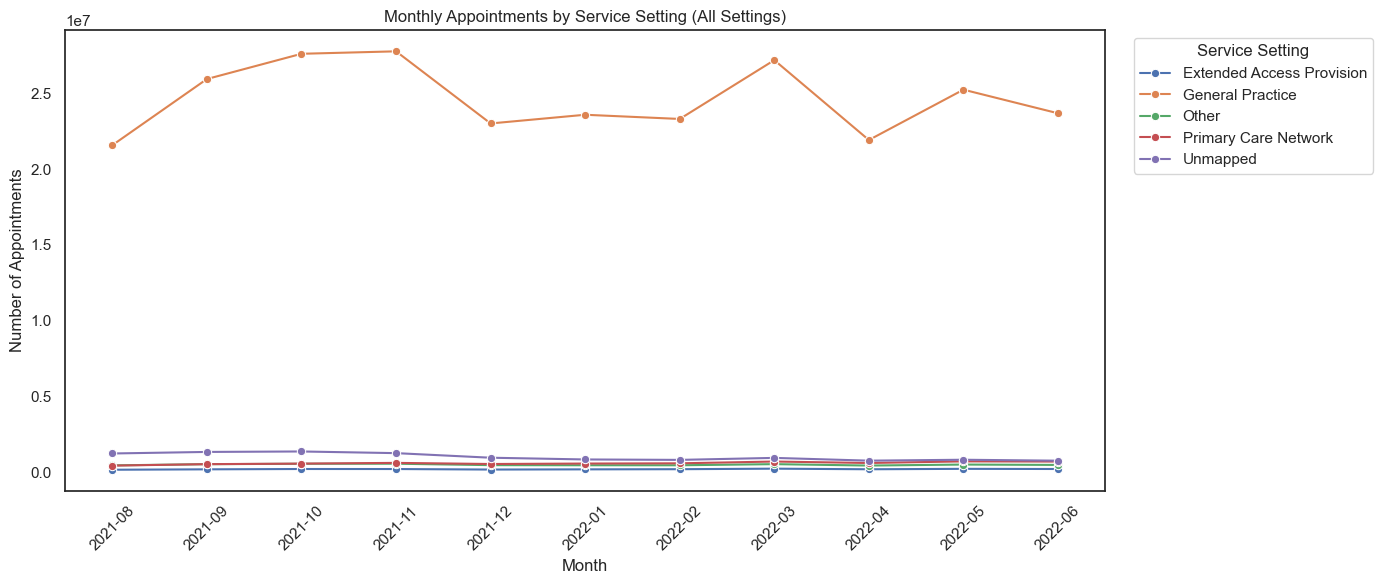

In [100]:
# Visualisation 1: all service settings
plt.figure(figsize=(14, 6))
sns.lineplot(x='year_month', y='count_of_appointments', hue='service_setting', data=nc_month_setting, marker='o', errorbar=None)
plt.title('Monthly Appointments by Service Setting (All Settings)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

# Save as PNG
plt.savefig('service_setting_all.png', dpi=300, bbox_inches='tight')
plt.show()

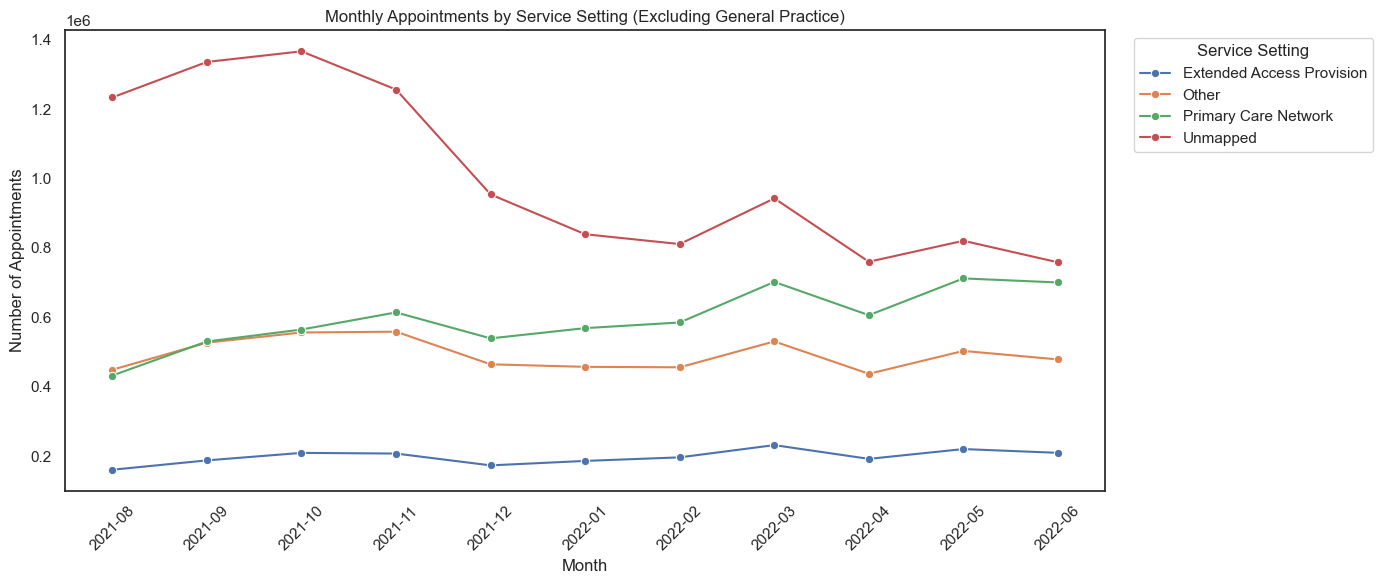

In [105]:
# Visualisation 2: excluding General Practice, to make the smaller service settings visible
# (General Practice's scale makes every other setting unreadable
# on a shared y-axis
nc_excl_gp = nc_month_setting[nc_month_setting['service_setting'] != 'General Practice']

plt.figure(figsize=(14, 6))
sns.lineplot(x='year_month', y='count_of_appointments',
             hue='service_setting', data=nc_excl_gp, marker='o', errorbar=None)
plt.title('Monthly Appointments by Service Setting (Excluding General Practice)')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.legend(title='Service Setting', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

plt.savefig('service_setting_excl_gp.png', dpi=300, bbox_inches='tight')
plt.show()

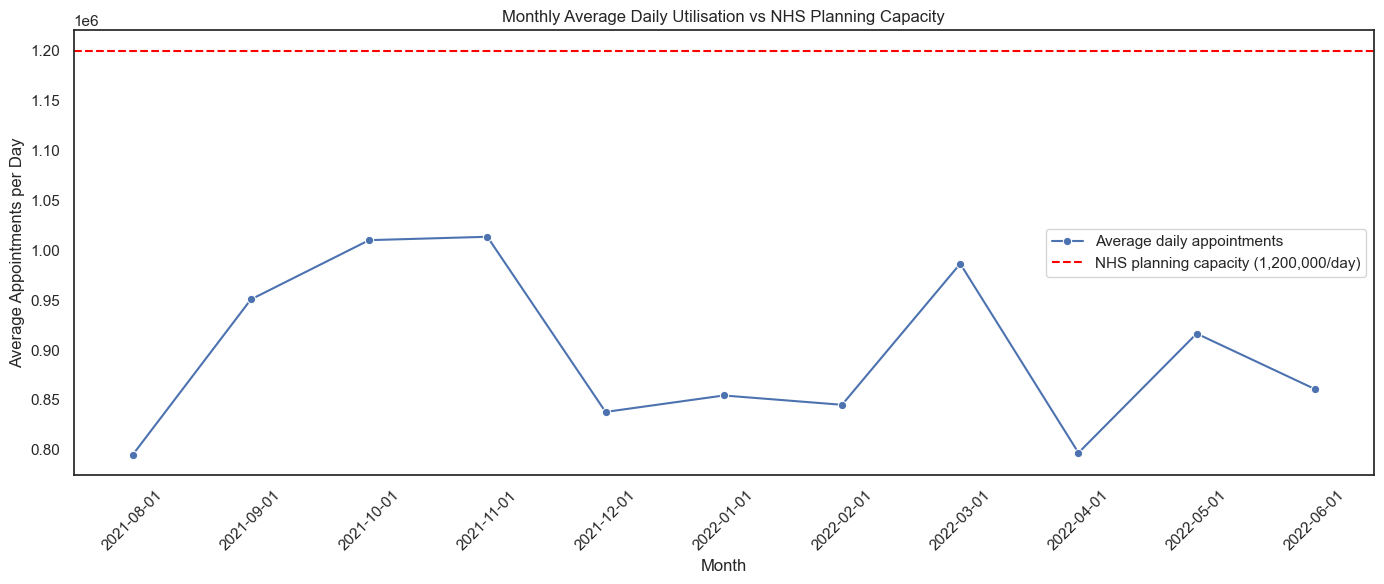

In [102]:
# Save the third required visualisation - the capacity utilisation chart from Question 1
# Re-generate it here with the savefig call included, so all three PNGs are produced
# consistently within this section of the notebook
plt.figure(figsize=(14, 6))
sns.lineplot(x='appointment_month', y='utilisation',
             data=ar_df, marker='o', errorbar=None, label='Average daily appointments')
plt.axhline(y=1200000, color='red', linestyle='--', label='NHS planning capacity (1,200,000/day)')
plt.title('Monthly Average Daily Utilisation vs NHS Planning Capacity')
plt.xlabel('Month')
plt.ylabel('Average Appointments per Day')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig('monthly_utilisation_vs_capacity.png', dpi=300, bbox_inches='tight')
plt.show()

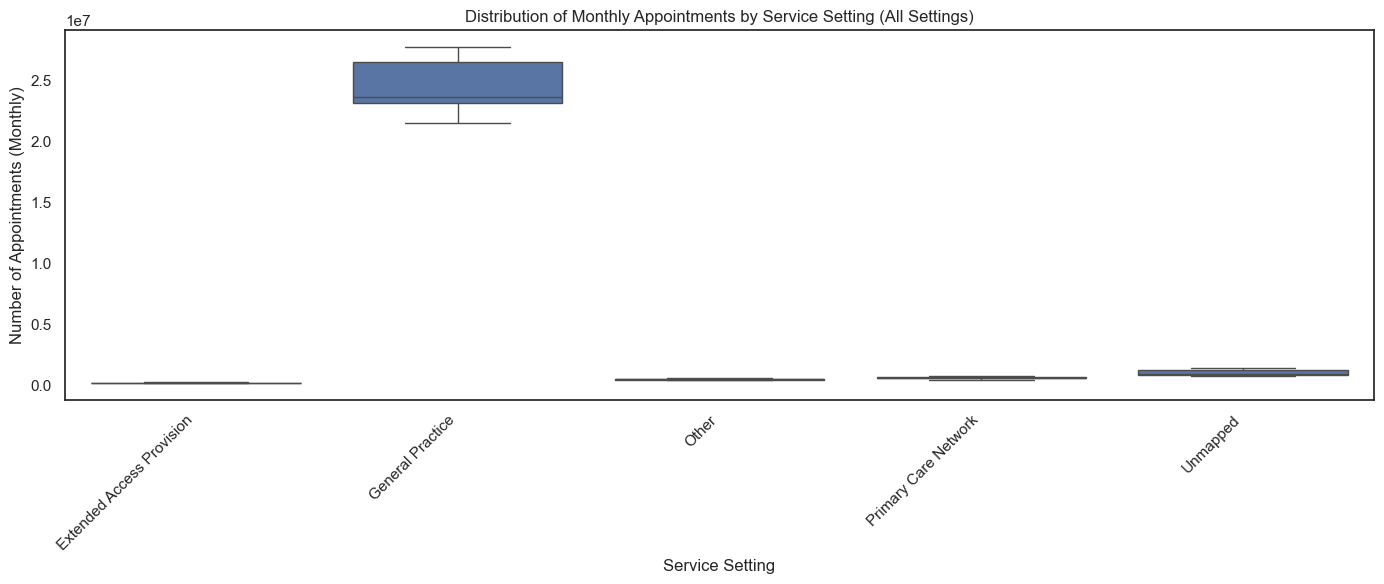

In [106]:
# Boxplot 1: distribution of monthly appointment counts across all service settings
# Unlike a lineplot (which shows the trend over time), a boxplot shows the spread and
# median of monthly appointment counts per service setting - useful for seeing which
# settings are consistently high/low vs which vary a lot month to month
plt.figure(figsize=(14, 6))
sns.boxplot(x='service_setting', y='count_of_appointments', data=nc_month_setting)
plt.title('Distribution of Monthly Appointments by Service Setting (All Settings)')
plt.xlabel('Service Setting')
plt.ylabel('Number of Appointments (Monthly)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save as PNG for inclusion in the report/presentation
plt.savefig('service_setting_boxplot_all.png', dpi=300, bbox_inches='tight')
plt.show()

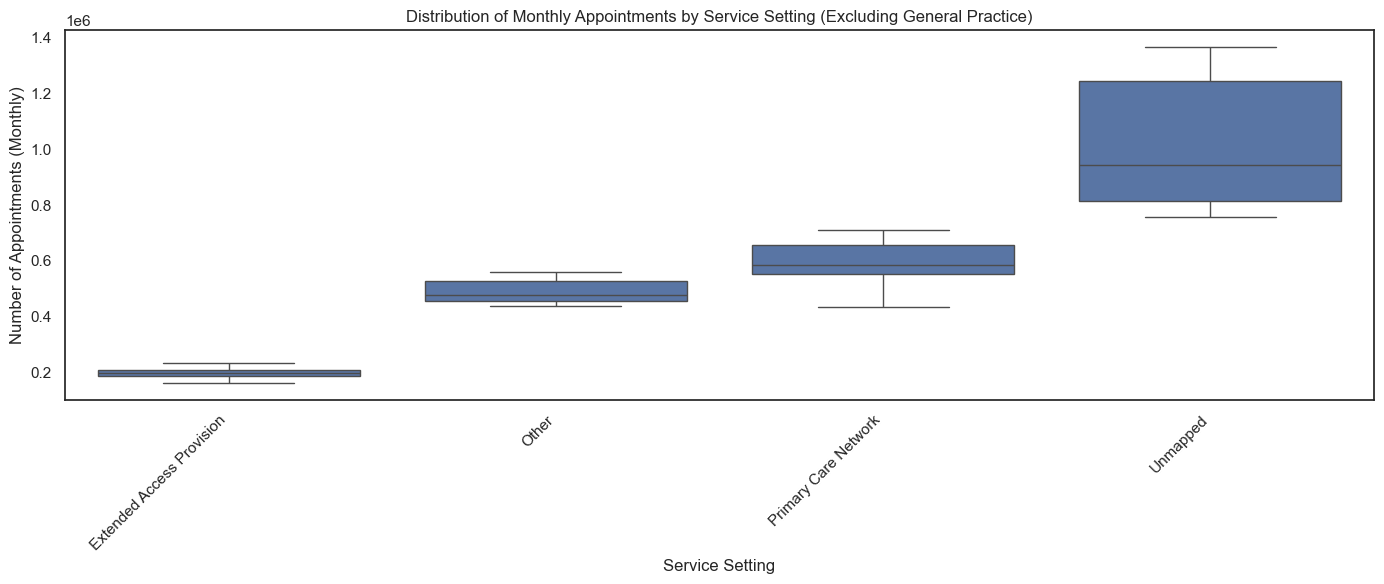

In [107]:
# Boxplot 2: same view, excluding General Practice
# General Practice's scale (seen in every chart so far) would otherwise compress all
# other boxes into an unreadable cluster near zero - excluding it lets the smaller
# service settings' distributions actually be compared to each other
nc_excl_gp = nc_month_setting[nc_month_setting['service_setting'] != 'General Practice']

plt.figure(figsize=(14, 6))
sns.boxplot(x='service_setting', y='count_of_appointments', data=nc_excl_gp)
plt.title('Distribution of Monthly Appointments by Service Setting (Excluding General Practice)')
plt.xlabel('Service Setting')
plt.ylabel('Number of Appointments (Monthly)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig('service_setting_boxplot_excl_gp.png', dpi=300, bbox_inches='tight')
plt.show()

# Summary of findings and recommendations based on the analysis.

### 1. Data quality gaps are large enough to distort every other finding

Roughly a third of appointment_status rows, a fifth of hcp_type rows, and a meaningful share of service_setting/context_type values are recorded as "Unknown," "Unmapped," or "Inconsistent Mapping." Critically, once weighted by actual appointment volume rather than row count, "Unmapped" is the largest non-GP service setting and is larger than Primary Care Network, Other, or Extended Access Provision combined. This means the NHS currently cannot reliably say what a meaningful share of its own second-tier capacity is actually being used for.

### 2. Monthly average utilisation looks comfortable, but the metric itself is misleading

Average daily utilisation peaks at around 1.01 million appointments/day (Oct–Nov 2021), against the NHS's stated 1,200,000/day capacity benchmark, never breaching it, even at the busiest point. Taken at face value, this says capacity is adequate. But the daily level charts in Activity 4, cell 58, show appointments are concentrated almost entirely on weekdays, with near-zero volume on weekends. Dividing by a flat 30-day month dilutes this and understates true weekday peak load.

### 3. The seasonal demand pattern is consistent and actionable

An October - November 2021 peak, a December dip (tied to reduced holiday period clinic operation, not falling demand), and a second March 2022 peak appear consistently across every single breakdown tested, including service setting, context type, national category, HCP type, appointment mode, and daily level charts. This consistency across independent slices of the data gives high confidence this is genuine demand seasonality.

### 4. Missed appointments (DNA) are far less severe than the raw data first suggested

Counting distinct records, DNA (Did Not Attend) appeared to affect 27% of rows. But weighted by actual appointment volume, DNA accounts for only roughly 4–5% of total monthly appointments, while Attended appointments dominate volume overwhelmingly (about 90%+). This is a materially different, and more reassuring, picture than the row-level statistic implied.

### 5. Most patients are seen same-day; access is better than commonly assumed

"Same Day" is the single largest booking-lead-time category every month, well ahead of longer wait bands. Long waits (22+ days) are a comparatively small share of total volume.

### 6. Non-GP staff already carry a substantial share of the workload

"Other Practice staff" appointments run nearly as high in volume as GP-attributed appointments in appointments_regional, month over month as seen in cell 89. This suggests care delivery is already more distributed across staff types than a "GP capacity" framing alone would imply.

### 7. Twitter/X data adds limited but genuine supplementary value

Hashtag analysis is useful for surfacing topic-level public conversation, but the sample lacks timestamps, cannot be linked to the appointment trend timeline, and does not reflect the general patient population. This can be used as a secondary, qualitative signal only and not as evidence for the core capacity/utilisation issues.

# Recommendations

The most immediate and lowest cost action the NHS should take is fixing the data mapping and capture process behind appointment_status, hcp_type, and service_setting. This is not a resourcing decision and can be dealt with right away by the data/reporting team. Because a meaningful share of records currently fall into "Unknown," "Unmapped," or "Inconsistent Mapping" categories, every other statistic in this analysis such as DNA rates, staffing splits, service setting breakdowns carries more uncertainty than it should. Addressing this first is the single highest-leverage step available as it costs little, requires no new investment in capacity, and materially improves the reliability of every figure the NHS will use to make future decisions.



The NHS should also correct the internal and public narrative around missed appointments. Counted by number of records, DNA appointments appear to affect 27% of the data, but once weighted by actual appointment volume, DNA accounts for only around 4–5% of total monthly appointments which is a far less severe picture. Communicating this corrected figure matters, since a policy response built on the inflated row-count statistic risks being disproportionate, and runs counter to responses to missed appointments without first understanding their true scale and causes.

Also, the NHS should plan flexible seasonal staffing around the October - November and March periods, which consistently emerge as demand peaks across every breakdown in this analysis: service setting, context type, national category, staff type, appointment mode, and daily-level detail. This consistency across independent measures gives high confidence that the pattern is genuine seasonal demand rather than a reporting issue, making it one of the more actionable findings in the whole analysis. At the same time, the NHS should avoid further reducing clinic availability over the December holiday period, since the data shows this dip reflects reduced operating days rather than falling patient demand; cutting further here would risk compounding a gap that isn't demand driven in the first place.

Longer term, the NHS should investigate whether its strong same-day access, which is the largest single booking lead time category throughout the dataset, is being achieved at the expense of longer-planned or chronic care appointments, since the current data cannot yet distinguish between these two possibilities.

Also, the Twitter/X data has been treated as a supplementary, qualitative signal rather than a primary evidence source for capacity or utilisation decisions. The current sample lacks timestamps, cannot be linked to the appointment trends identified elsewhere in this analysis, and reflects the views of vocal social media users rather than the general patient population. A small scale pilot to monitor hashtag activity as an early warning layer is reasonable, but it cannot be resourced ahead of the higher impact, data-driven recommendations above.